# Image-image alignment evaluation — ArabicData2

Copy of `model_evaluation.ipynb`: same 188-cell layout, numerical matching
parameters, representation controls, sampling limits and optional diagnostics.

**Checkpoint:** `real_arabicdata2_ab_all80_20261112/checkpoint_best.pt`.
Its training identities map to **A = BnF_btv1b11003097s** and
**B = Leeds_iskandar_ms153** through the CSV `original_line_number` fields.
The current numbered exports repeat the same physical lines across comparisons.
Copies are verified and deduplicated for feature caching; partners are read from
`line` / `other_line`, and membership is recovered from the checkpoint's original
line IDs. Only available exported lines are evaluated; the full training inventory
is not present. Page membership is checked for leakage before use.

The word decoder builds a fixed vocabulary from **available saved-training lines
only**, with the same vocabulary filtering rules. This is a partial training
vocabulary, not a reconstruction of missing historical transcripts. Original
matching and A–B confidence values are transferred unchanged; they have not been
recalibrated for this checkpoint. No evaluated transcripts enter predictions.

**Current mode: qualitative inspection only.** No ground-truth masks are
loaded, generated or replaced with black masks. Figures show the source images,
predicted masks/overlays, similarity heatmaps and predicted routes. Route scores
and feature statistics describe model behavior; they are not accuracy measures.
CSV partners and presumed non-partners select examples, not pixel-level truth.

Ground-truth displays, accuracy tables, quantitative population evaluation and
supervised recognition/ranking are disabled. Their section positions are retained
for later work after mask annotation. No historical results are carried over.

**Transcript review:** full A/B transcripts include color-coded shared text spans.
Each accepted predicted image region includes paired source crops/overlays and
the model's word hypothesis, so the reference words can be checked visually.
Text highlights are for comparison; no spatial ground truth or accuracy is inferred.


# Image-image alignment evaluation

All sample, negative, population, mask and metric predictions use the repository's
`match_features()` entry point through `predict_cached_pair()` / `EvaluationSession`.
Model inference is cached; matcher changes do not retrain or change the network.
Outputs are cleared; run the cells with the active settings below.

1. Imports and model/data configuration
2. Load checkpoint/session
3. Active matcher configuration (printed in full)
4. Select and visualize aligned samples (independent slots)
5. Select and visualize unaligned samples
6. Candidate diagnostics and population quantitative evaluation
7. Optional parameter validation and supervised recognition diagnostics

This notebook currently runs qualitative diagnostics only, without ground-truth masks.
Matching parameters remain fixed; quantitative scoring is deferred until annotation.


Each Sample N group selects one pair, then provides separate LOCAL, FUSED, and CONTEXT code cells in that order. The three output cells reuse the same saved pair and can be rerun independently. Fixed Phase 1 examples near the end use separate representation cells as well.

Evaluation uses **DataSet/ArabicData2**. Its CSV records select positive partners;
seeded cross-book combinations excluding recorded partners, identical images and
shared normalized words supply presumed negatives. Both sides must belong to the
same saved checkpoint split. No transcript or mask enters visual prediction.

No supplied mask files exist in this export. Only predicted masks are shown.
No ground-truth placeholders or accuracy scores are produced.

[View retained review slots](#book-pair-samples)


Run the setup cell below whenever the model or dataset changes. It applies the settings and refreshes the project imports together, then prints the resolved paths before loading the session.


## 1. Load the checkpoint once

This stage loads the frozen model and checkpoint split membership, builds the positive-pair catalog, and caches extracted line features. It does **not** depend on the similarity threshold. Run it once per checkpoint, dataset, device, or split change.


In [115]:
# MODEL/DATA SETUP. This cell refreshes settings AND project imports together.
# Matcher settings remain in their separate cell; tuning them does not reload the model.
CHECKPOINT = "Weights/real_arabicdata2_ab_all80_20261112/checkpoint_best.pt"
DATASET = "DataSet/ArabicData2"
EVALUATION_CROP = "none"  # Preserve the full-line geometry used in training.
PAIR_SOURCE = "csv"                  # ArabicData2 recorded line/other_line partners
NEGATIVE_POOL_SIZE = 100             # bounded seeded comparison pool for the saved split
SPLIT = "test"
ALLOW_SPLIT_FALLBACK = True          # label any qualitative split fallback explicitly
NUM_SAMPLES = 10                      # how many independent sample cells run on "Run All" (1..10)
RANDOM_SEED = 42
DEVICE = "mps"                       # 'auto', 'mps', 'cuda', or 'cpu'
REPRESENTATION = "fused"             # primary for optional tools
SHOW_REPRESENTATIONS = ["fused"]  # choose which to display, e.g. ["fused"] or "all"
SHOW_TRANSCRIPTS = True              # reference text + shared phrases, after prediction
SHOW_ALIGNED_REGION_CROPS = True     # source crops + predicted word hypotheses
SHOW_GT_MASKS = False                 # pair matching; recognition always uses fused vectors
REQUIRE_GROUND_TRUTH = False
ANNOTATION_MANIFEST = None

# Optional recognition/inspection (not run unless their own cells are enabled).
RECOGNITION_SLOT = 1
ENABLE_RECOGNITION_TABLES = False
ENABLE_RECOGNITION_METRICS = False
ENABLE_RECOGNITION_HEATMAPS = False
TOP_K = 5
SHOW_ALPHABET_HEATMAP = True
MARK_TOP1 = True
INSPECT_SLOT = 1
INSPECT_LINE = "A"
WINDOW_INDEX = 5
SHOW_WINDOW_INSPECTOR = False

# Optional saving: only the selected slot, and only when you explicitly enable it.
SAVE_RESULTS = False
SAVE_SLOT = 1
RESULTS_ROOT = "Results/Evaluation/arabicdata2"
# Optional population evaluation and diagnostics.
RUN_POPULATION_EVALUATION = False
POPULATION_MAX_PAIRS = 0  # retained for legacy tools; A–B counts below are independent
QUANTITATIVE_ALIGNED_PAIRS = 300
QUANTITATIVE_UNALIGNED_PAIRS = 300
QUANTITATIVE_SEED = 42
QUANTITATIVE_WORKERS = 1  # bound memory on this 8 GB machine; completed predictions are cached
QUANTITATIVE_OUTPUT = "Results/Evaluation/arabicdata2/ab_300_low_fpr"
AB_CONFIDENCE_PRESET = "docs/evaluation/ab_low_fpr_20261109/selected.json"
RUN_SIMILARITY_COMPARISON = False
RUN_RANKING_DIAGNOSTIC = False

_ALL_REPRESENTATIONS = ("local", "fused", "context")
SHOWN_REPRESENTATIONS = (_ALL_REPRESENTATIONS if SHOW_REPRESENTATIONS == "all"
                         else tuple(r for r in _ALL_REPRESENTATIONS if r in SHOW_REPRESENTATIONS))
_unknown = set([SHOW_REPRESENTATIONS] if isinstance(SHOW_REPRESENTATIONS, str) else SHOW_REPRESENTATIONS) \
    - set(_ALL_REPRESENTATIONS) - {"all"}
if _unknown or not SHOWN_REPRESENTATIONS:
    raise ValueError(f"SHOW_REPRESENTATIONS must be 'all' or a non-empty subset of {_ALL_REPRESENTATIONS}; got {SHOW_REPRESENTATIONS!r}")

N_POSITIVE_SAMPLES = NUM_SAMPLES
N_NEGATIVE_SAMPLES = NUM_SAMPLES

import sys, json, hashlib, uuid, unicodedata, random, time
import numpy as np
import pandas as pd
import matplotlib
if 'get_ipython' in globals() and get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import torch

from pathlib import Path
_here = Path.cwd().resolve()
ROOT = next((p for p in (_here, *_here.parents) if (p / "evaluation_utils.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from AlignmentProject or its notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Refresh display code even when this kernel imported it before the edit.
import importlib as _overlay_importlib
for _overlay_module_name in ("parameters", "text_embedding", "dtw", "losses", "dataset", "dataloader",
                             "train", "word_alignment", "evaluate", "alignment_overlays", "evaluation_utils", "evaluation_presets"):
    _overlay_importlib.reload(_overlay_importlib.import_module(_overlay_module_name))

from collections import Counter
from evaluation_utils import (
    EvaluationSession, positive_pairs, shuffled_positive_pairs,
    plot_pair_alignment, save_pair_artifacts,
    predict_cached_pair, print_candidate_diagnostics, set_line_window_axis,
)
from evaluate import source_interval, resolved_match_settings, MATCH_VERSION
from dtw import cosine_similarity_matrix, letter_cost_matrix, hard_dtw_path
from dataset import prepare_image
from text_embedding import ARABIC_LETTERS, clean_letters
from IPython.display import display



ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "model.py").is_file() and (p / "evaluate.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from AlignmentProject or its notebooks/ directory.")
sys.path.insert(0, str(ROOT))

print(f"Using ROOT: {ROOT}")

def project_path(value):
    if value is None:
        return None
    path = Path(value).expanduser()
    return path if path.is_absolute() else ROOT / path

def build_session(split):
    # No threshold/matcher settings are passed to model/session construction.
    if 'QualitativeEvaluationSession' not in globals():
        raise RuntimeError('Run the QUALITATIVE SESSION cell before session setup.')
    return QualitativeEvaluationSession(
        project_path(CHECKPOINT), project_path(DATASET), split=split, device=DEVICE,
        seed=RANDOM_SEED, pair_source=PAIR_SOURCE, construct_negatives=True,
        negative_count=NEGATIVE_POOL_SIZE,
        annotation_manifest=project_path(ANNOTATION_MANIFEST), crop_override=EVALUATION_CROP)

# Session is built exactly once in the next cell.


Using ROOT: /Users/ahmedmas/Desktop/AlignmentProject


In [116]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [117]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


### Preprocessing follows the trained image geometry

`EVALUATION_CROP = "none"` preserves the full exported line before resizing, as in training. Cropping margins changed the scale of C writing and reduced several cross-book alignments. `content` remains available as an explicitly reported preprocessing experiment.


In [118]:
# INPUT CROP DISPLAY — preprocessing is implemented in dataset.prepare_image().
SHOW_CROP_PREVIEW = True
from PIL import Image
print('Evaluation preprocessing crop:', EVALUATION_CROP)

# All line images/masks use heatmap window indices: RTL ticks 60, 50, 40, ..., 0.
# Reload the notebook and Restart Kernel / Run All to replace already rendered pixel axes.


Evaluation preprocessing crop: none


### Qualitative predictions without ground-truth masks

Show the source lines, predicted masks, color overlays, cosine/reward heatmaps
and predicted matching routes for each representation. Predicted masks are model
outputs for visual inspection. No annotation masks are loaded or synthesized.

Pixel accuracy, IoU, Dice, precision/recall and alignment correctness are deferred
until masks are annotated. CSV partner labels only select review examples;
constructed non-partners remain presumed negatives, not verified no-overlap truth.

Full reference transcripts appear above each sample figure. Matching T labels
highlight shared text spans, including reordered passages, without assuming image
coordinates. For every accepted R region, review the original image crop,
predicted overlay, decoded word hypothesis (when available), and its occurrences
in each transcript. These displays run after prediction and do not alter matching.

Source lines, predicted overlays and masks are displayed at their original pixel
dimensions. Wide images scroll horizontally. Region crops retain their original
pixel resolution and are not enlarged to fill a table cell. Heatmaps remain plots.
Checkpoint input preprocessing and matching parameters are unchanged.


In [119]:
# ARABICDATA2 CSV ADAPTER — shared feature/matcher APIs remain unchanged.
import csv
import tempfile
from dataclasses import replace
from dataset import file_hash, AlignmentDataset
from copy import copy
from dataloader import collate_samples
from torch.utils.data import DataLoader
from train import build_loaders, load_checkpoint
from evaluation_utils import DEFAULT_MATCH_SETTINGS, _side_key, _normalized_unit

ARABICDATA2_BOOKS = {'A': 'BnF_btv1b11003097s', 'B': 'Leeds_iskandar_ms153'}


class ArabicData2EvaluationSession(EvaluationSession):
    """Recover saved original-line membership for the current CSV export."""
    def __init__(self, checkpoint, dataset, split='test', device='auto', seed=42,
                 settings=None, construct_negatives=True, negative_count=None,
                 annotation_manifest=None, pair_source='csv', crop_override=None):
        if split not in ('train', 'val', 'test') or pair_source != 'csv':
            raise ValueError('Use train/val/test and pair_source="csv" for ArabicData2')
        if annotation_manifest is not None:
            raise ValueError('This adapter uses source CSV partners and optional folder masks')
        self.checkpoint = Path(checkpoint).expanduser().resolve()
        self.dataset_path = Path(dataset).expanduser().resolve()
        self.device = torch.device(('cuda' if torch.cuda.is_available() else
            'mps' if torch.backends.mps.is_available() else 'cpu') if device == 'auto' else device)
        self.model, self._text_encoder, self.config, self.saved = load_checkpoint(
            self.checkpoint, self.device, load_text=False)
        self.crop_override = crop_override
        if crop_override is not None:
            self.config = replace(self.config, crop=crop_override)
        self.model.eval()
        self.split, self.seed = split, seed
        self.settings = dict(DEFAULT_MATCH_SETTINGS, **(settings or {}))
        self.pair_source = pair_source
        self._book_aliases = tempfile.TemporaryDirectory(prefix='arabicdata2-evaluation-')
        alias_root = Path(self._book_aliases.name)
        rows = {}
        for name, folder in ARABICDATA2_BOOKS.items():
            physical = self.dataset_path / folder
            (alias_root / ('Book' + name)).symlink_to(physical, target_is_directory=True)
            with (physical / 'align/alignments.csv').open(encoding='utf-8-sig', newline='') as stream:
                rows[name] = list(csv.DictReader(stream))
        # Recover original training IDs rather than interpreting comparison IDs
        # as line IDs. One original line can appear in many numbered exports.
        data = AlignmentDataset(alias_root, 'real', paired=False, books=('A', 'B'),
            image_size=(self.config.image_height, self.config.image_width),
            grayscale=self.config.grayscale, crop=self.config.crop, binarize=self.config.binarize)
        csv_rows = {book: {row['line']: row for row in entries} for book, entries in rows.items()}
        canonical, signatures = {}, {}
        export_to_original = {}
        for record in data.records:
            book = record['book_id']
            export_id = record['sample_id'].split(':', 1)[1]
            row = csv_rows[book][export_id]
            sid = 'Book' + book + ':' + row['original_line_number']
            export_to_original[(book, export_id)] = sid
            side = record['sides'][0]
            signature = (file_hash(side['image']), Path(side['text']).read_text(
                encoding='utf-8').strip(), record['group_id'])
            if sid in signatures and signatures[sid] != signature:
                raise ValueError('Conflicting exported copies for checkpoint line ' + sid)
            signatures[sid] = signature
            record['sample_id'] = sid
            canonical.setdefault(sid, record)
        saved_membership = {sid: name for name, ids in self.saved['split_ids'].items() for sid in ids}
        missing = sorted(set(canonical) - set(saved_membership))
        if missing:
            raise ValueError('CSV original IDs absent from this checkpoint: ' + str(missing[:10]))
        pages = {}
        self.views = {}
        for name in ('train', 'val', 'test'):
            view = copy(data)
            view.records = [record for sid, record in canonical.items() if saved_membership[sid] == name]
            view.augment = False
            view.evaluation_view = True
            view.negative_config = self.config if name in ('train', 'val') else None
            for record in view.records:
                pages.setdefault(record['group_id'], set()).add(name)
            self.views[name] = view
        if any(len(names) > 1 for names in pages.values()):
            raise ValueError('Recovered original-line IDs leak pages across saved splits; check book mapping')
        image_splits = {}
        for sid, signature in signatures.items():
            image_splits.setdefault(signature[0], set()).add(saved_membership[sid])
        if any(len(names) > 1 for names in image_splits.values()):
            raise ValueError('Identical images cross recovered checkpoint splits')
        self._loaders = [DataLoader(self.views[name], batch_size=self.config.batch_size,
            shuffle=False, num_workers=0, collate_fn=collate_samples) for name in ('train', 'val', 'test')]
        self.view = self.views[split]
        self.split_sizes = {name: len(view) for name, view in self.views.items()}
        self.evaluation_split_ids = {name: [r['sample_id'] for r in view.records]
                                     for name, view in self.views.items()}
        self.available_subset_sha256 = hashlib.sha256(json.dumps(
            self.evaluation_split_ids, sort_keys=True).encode()).hexdigest()
        self.split_provenance = dict(scope='available subset of checkpoint saved original-line membership',
            checkpoint_membership_replayed=True, book_mapping=ARABICDATA2_BOOKS,
            available_subset_sha256=self.available_subset_sha256,
            checkpoint_split_sha256=self.saved['split_manifest_sha256'])
        self.allowed = {}
        members = {}
        for record in self.view.records:
            side = record['sides'][0]
            side['book_id'] = record['book_id']
            members[record['sample_id']] = record
            self.allowed[_side_key(side)] = dict(side=side, group_id=record['group_id'],
                                                 pair_ids=set(), anchors=set())
        self.line_aliases, self.feature_cache, self.metric_cache = {}, {}, {}
        self.pairs, self.excluded_pairs, self.unknown_labels = [], 0, {}
        partner_keys = set()
        reverse_rows = {(r['line'], r['other_line']): r for r in rows['B']}
        for row in rows['A']:
            if row['other_book'] != ARABICDATA2_BOOKS['B']:
                raise ValueError('Unexpected other_book in ArabicData2 A catalog')
            partner = reverse_rows.get((row['other_line'], row['line']))
            if partner is None or partner['other_book'] != ARABICDATA2_BOOKS['A']:
                raise ValueError('ArabicData2 CSV partner relationship is not reciprocal')
            ids = (export_to_original[('A', row['line'])], export_to_original[('B', row['other_line'])])
            partner_keys.add(ids)
            if not all(sid in members for sid in ids):
                self.excluded_pairs += 1
                continue
            records = [members[sid] for sid in ids]
            self.pairs.append(dict(sample_id='ArabicData2:csv:' + row['pair_number'],
                sides=[r['sides'][0] for r in records], target=1, label='stored_aligned_pair',
                constructed_negative=False, group_ids=[r['group_id'] for r in records],
                annotations=[{}, {}], anchor_id='', book_pair='A_B',
                annotation_provenance='CSV recorded partner; no supplied localization masks',
                source_csv_splits=[row['split'], partner['split']], original_ids=list(ids)))
        # Reservoir sampling keeps the same bounded, seeded negative-pool control.
        rng, candidates, seen = random.Random(seed), [], 0
        count = (negative_count if negative_count is not None else len(members)) if construct_negatives else 0
        if count < 0:
            raise ValueError('negative_count must be nonnegative')
        words = {sid: {_normalized_unit(w) for w in Path(r['sides'][0]['text']).read_text(
            encoding='utf-8').split()} - {''} for sid, r in members.items()}
        hashes = {sid: file_hash(r['sides'][0]['image']) for sid, r in members.items()}
        for aid, a in sorted(members.items()):
            if not aid.startswith('BookA:'):
                continue
            for bid, b in sorted(members.items()):
                if (not bid.startswith('BookB:') or (aid, bid) in partner_keys or
                        words[aid] & words[bid] or hashes[aid] == hashes[bid]):
                    continue
                seen += 1
                candidate = (aid, bid, a, b)
                if len(candidates) < count:
                    candidates.append(candidate)
                elif count:
                    slot = rng.randrange(seen)
                    if slot < count:
                        candidates[slot] = candidate
        for aid, bid, a, b in candidates:
            self.pairs.append(dict(sample_id='ArabicData2:negative:' + aid + ':' + bid,
                sides=[a['sides'][0], b['sides'][0]], target=0,
                label='unmatched_lines_presumed_negative', constructed_negative=True,
                group_ids=[a['group_id'], b['group_id']], annotations=[{}, {}], anchor_id='',
                book_pair='A_B', annotation_provenance='presumed negative; no supplied masks'))
        self.provided_negative_count = 0
        self.folder_summary = dict(recorded_csv_partners=sum(p['target'] == 1 for p in self.pairs),
            sampled_presumed_negatives=len(candidates), eligible_negative_combinations=seen)
        self.checkpoint_sha256 = file_hash(self.checkpoint)
        print('ArabicData2 membership:', self.split_provenance)


# QUALITATIVE SESSION — prediction descriptions only, with no GT scoring.
from evaluation_presets import settings_for_pair
from evaluation_utils import representation_diagnostics


def describe_prediction(result, config):
    """Summarize image features and accepted routes without consulting annotations."""
    pair, match = result['pair'], result['match']
    diagnostics = representation_diagnostics(result)
    metrics = dict(diagnostics,
        sample_id=pair['sample_id'], label=pair['label'], target=pair['target'],
        split=result['split'], representation=result['representation'],
        image_a=pair['sides'][0]['image'], image_b=pair['sides'][1]['image'],
        constructed_negative=pair['constructed_negative'],
        pair_score=max((r['score'] for r in match['regions']), default=0.),
        accepted_region_score_sum=sum(r['score'] for r in match['regions']),
        path_length=diagnostics['number_of_matched_pairs'], region_count=len(match['regions']),
        path_cosine_mean=diagnostics['path_mean_cosine'],
        path_cosine_median=diagnostics['path_median_cosine'],
        path_cosine_min=diagnostics['path_min_cosine'],
        maximum_similarity=diagnostics['matrix_max'], matrix_cosine_mean=diagnostics['matrix_mean'],
        off_path_cosine_mean=diagnostics['off_path_mean_cosine'],
        similarity_separation=diagnostics['path_contrast'],
        similarity_mode=result['settings']['similarity_mode'], decoder=result['settings']['decoder'],
        evaluation_category='qualitative (unannotated)')
    for index, name in enumerate(('a', 'b')):
        metrics['mask_coverage_' + name] = float((np.asarray(result['masks'][index]) > 0).mean())
        metrics['matched_windows_' + name] = diagnostics['distinct_windows_' + name]
        metrics['total_windows_' + name] = len(result['lines'][index]['physical'])
    result.update(metrics=metrics, ground_truth=[None, None])
    return result


class QualitativeEvaluationSession(ArabicData2EvaluationSession):
    """Reuse checkpoint/features; never load annotations or calculate accuracy."""
    def predict_pair(self, pair, representation='fused'):
        effective = settings_for_pair(pair, self.settings, globals().get('PAIR_MATCH_OVERRIDES', {}))
        lines = [self.get_line_features(side) for side in pair['sides']]
        return predict_cached_pair(self, pair, lines, representation, settings=effective)

    def matching_cache_key(self, pair, representation='fused'):
        effective = settings_for_pair(pair, self.settings, globals().get('PAIR_MATCH_OVERRIDES', {}))
        return (*super().matching_cache_key(pair, representation), json.dumps(effective, sort_keys=True))

    def evaluate_pair(self, pair, representation='fused'):
        return describe_prediction(self.predict_pair(pair, representation), self.config)

    def summary(self):
        info = dict(dataset=str(self.dataset_path), split=self.split, crop=self.config.crop,
            pairs=len(self.pairs), recorded_partners=sum(p['target'] == 1 for p in self.pairs),
            presumed_nonpartners=sum(p['target'] == 0 for p in self.pairs), mode='qualitative only')
        print(info)
        return info


# TRANSCRIPT REVIEW — reference text is read only after visual prediction.
import base64
import html
import io
import math
import re
from PIL import Image
from IPython.display import HTML
from text_embedding import read_side_text
from word_alignment import normalize_word
from evaluate import region_mask

_REVIEW_COLORS = ('#fff0aa', '#cceafc', '#d5f3d0', '#f6d8ed', '#e4dcff', '#ffd9bd')


def review_tokens(text):
    return [dict(text=m.group(), start=m.start(), end=m.end(),
                 normalized=normalize_word(''.join(clean_letters(m.group()))))
            for m in re.finditer(r'\S+', text)]


def shared_transcript_spans(tokens):
    """Pair longest remaining common word runs, including reordered passages.

    This text-only display heuristic neither assigns image positions nor changes
    predictions. Repeated words can have several possible correspondences.
    """
    used = [set(), set()]
    spans = []
    while True:
        previous = [0] * (len(tokens[1]) + 1)
        best = (0, 0, 0)
        for i, a in enumerate(tokens[0]):
            current = [0] * (len(tokens[1]) + 1)
            for j, b in enumerate(tokens[1]):
                if (i not in used[0] and j not in used[1] and a['normalized'] and
                        a['normalized'] == b['normalized']):
                    current[j+1] = previous[j] + 1
                    if current[j+1] > best[0]:
                        best = (current[j+1], i+1-current[j+1], j+1-current[j+1])
            previous = current
        length, a, b = best
        if not length:
            return spans
        spans.append(dict(id='T' + str(len(spans)+1), ranges=[(a,a+length),(b,b+length)]))
        for side, start in enumerate((a,b)):
            used[side].update(range(start,start+length))


def marked_transcript(text, tokens, spans, side):
    intervals = []
    for k, span in enumerate(spans):
        start, end = span['ranges'][side]
        intervals.append((tokens[start]['start'], tokens[end-1]['end'], span['id'], _REVIEW_COLORS[k % len(_REVIEW_COLORS)]))
    parts, cursor = [], 0
    for start, end, label, color in sorted(intervals):
        parts.append(html.escape(text[cursor:start]))
        parts.append(f'<mark style="background:{color};padding:2px;border-radius:4px">'
                     f'{html.escape(text[start:end])}<sup dir="ltr" style="font:11px sans-serif"> {label}</sup></mark>')
        cursor = end
    parts.append(html.escape(text[cursor:]))
    return ''.join(parts)


def image_data_url(image):
    buffer = io.BytesIO()
    image.save(buffer, format='PNG')
    return 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode('ascii')


def native_image_html(image, label):
    """Render one source pixel per CSS pixel, with scroll instead of scaling."""
    width,height=image.size
    style=(f'display:block!important;width:{width}px!important;height:{height}px!important;'
           'min-width:0!important;max-width:none!important;max-height:none!important;'
           'object-fit:none!important;transform:none!important;flex:none!important')
    return (f'<div style="margin:8px 0"><div>{html.escape(label)} — {width} × {height} px</div>'
            '<div style="display:block;max-width:100%;overflow-x:auto;overflow-y:auto;direction:ltr">'
            f'<img alt="{html.escape(label,quote=True)}" width="{width}" height="{height}" '
            f'src="{image_data_url(image)}" style="{style}"></div></div>')


def display_native_sources(pair):
    sections=[]
    for name,side in zip(('A','B'),pair['sides']):
        with Image.open(side['image']) as source:
            image=source.copy()
        sections.append(native_image_html(image,f'Line {name} — original / {Path(side["image"]).name}'))
    display(HTML(''.join(sections)))


def native_pair_images_html(session,result):
    from alignment_overlays import aligned_window_overlays
    originals=[]
    for side,line,mask in zip(result['pair']['sides'],result['lines'],result['masks']):
        with Image.open(side['image']) as source:
            image=source.convert('RGB')
        if image.size != tuple(line['geometry']['source_size']):
            raise ValueError('Source dimensions differ from prediction geometry')
        if np.asarray(mask).shape != (image.height,image.width):
            raise ValueError('Predicted mask must have the original source dimensions')
        originals.append(image)
    overlays=aligned_window_overlays(originals,result['masks'],result['match']['regions'],
        [line['physical'] for line in result['lines']],
        [line['geometry'] for line in result['lines']],
        session.config.window_width,session.config.window_stride)
    sections=['<h4>Source images and predictions — original pixel dimensions</h4>']
    for index,name in enumerate(('A','B')):
        sections.append(native_image_html(originals[index],f'Line {name} — original'))
        sections.append(native_image_html(Image.fromarray(overlays[index]),f'Line {name} — predicted overlay'))
        mask=Image.fromarray(((np.asarray(result['masks'][index])>0)*255).astype(np.uint8))
        sections.append(native_image_html(mask,f'Line {name} — predicted mask'))
    return ''.join(sections)


def transcript_review_data(result):
    """Return original reference strings and text-only shared spans for display."""
    texts = [read_side_text(side) for side in result['pair']['sides']]
    tokens = [review_tokens(text) for text in texts]
    return texts, tokens, shared_transcript_spans(tokens)


def display_transcript_review(session, result):
    if not globals().get('SHOW_TRANSCRIPTS', True):
        return
    texts, tokens, spans = transcript_review_data(result)
    arabic = 'direction:rtl;text-align:right;font:25px/1.9 "Noto Naskh Arabic","Geeza Pro",serif;white-space:pre-wrap'
    sections = [f'<div><h4>Reference transcripts — {html.escape(result["representation"].upper())}</h4>',
        '<p>Same T label/color = shared transcript phrase (normalized Arabic spelling). '
        'These text highlights are reference comparisons, not image annotations. '
        'Repeated words may have ambiguous correspondence.</p>']
    for side, name in enumerate(('A','B')):
        physical = ARABICDATA2_BOOKS[result['pair']['sides'][side]['book_id']]
        sections.append(f'<div style="border:1px solid #bbb;padding:12px;margin:8px 0;border-radius:6px">'
            f'<b>Line {name} — {html.escape(physical)}</b>'
            f'<div lang="ar" dir="rtl" style=\'{arabic}\'>'
            f'{marked_transcript(texts[side],tokens[side],spans,side)}</div></div>')
    if not spans:
        sections.append('<p>No shared normalized transcript words found.</p>')
    sections.append('</div>')
    display(HTML(''.join(sections)))

    if not globals().get('SHOW_ALIGNED_REGION_CROPS', True):
        return
    regions = result['match']['regions']
    if not regions:
        display(HTML('<p><b>No accepted image region.</b> Shared transcript highlights above '
                     'do not mean the model located those words.</p>'))
        return
    sections = ['<div><h4>Predicted aligned parts — image crops and decoded word hypotheses</h4>',
        '<p>Each R label identifies one accepted image region. The original crop is followed by '
        'its predicted overlay. A word hypothesis comes from the model; transcript occurrences '
        'are shown for comparison and do not establish its exact image location.</p>']
    for index, region in enumerate(regions):
        label = 'R' + str(index+1)
        word = region.get('word')
        hypothesis = (f'<span lang="ar" dir="rtl" style=\'{arabic}\'>{html.escape(word)}</span>'
                      if word else 'Visual passage — no decoded word hypothesis')
        sections.append(f'<div style="border:1px solid #bbb;padding:12px;margin:12px 0;border-radius:6px">'
                        f'<b>{label} — model hypothesis:</b> {hypothesis}'
                        '<table style="width:100%;table-layout:fixed"><tr>')
        for side, name in enumerate(('A','B')):
            line = result['lines'][side]
            physical = region['supported_physical'][side] + region.get('filled_physical',[[],[]])[side]
            intervals = [source_interval(int(v),line['geometry'],session.config.window_width,
                                         session.config.window_stride) for v in physical]
            if not intervals:
                sections.append(f'<td>Line {name}: no source interval available.</td>')
                continue
            with Image.open(result['pair']['sides'][side]['image']) as image:
                original = image.convert('RGB')
            left = max(0,math.floor(min(v[0] for v in intervals)))
            right = min(original.width,math.ceil(max(v[1] for v in intervals)))
            mask = region_mask([region],side,line['geometry'],session.config.window_width,
                               session.config.window_stride) > 0
            overlay = np.asarray(original).copy()
            overlay[mask] = (.60 * overlay[mask] + .40 * np.array([255,185,25])).astype(np.uint8)
            original_crop = original.crop((left,0,right,original.height))
            overlay_crop = Image.fromarray(overlay).crop((left,0,right,original.height))
            occurrences = [token['text'] for token in tokens[side] if word and
                           token['normalized'] == normalize_word(''.join(clean_letters(word)))]
            reference = (' / '.join(occurrences) if occurrences else
                         'Word absent from transcript' if word else 'No word hypothesis to compare')
            sections.append(f'<td style="vertical-align:top;padding:8px"><b>{label} / Line {name}</b>'
                f'<div>Source x: [{left}, {right})</div>'
                f'<div>Transcript occurrence(s): <span lang="ar" dir="rtl">{html.escape(reference)}</span></div>'
                + native_image_html(original_crop,f'{label} / Line {name} — original crop')
                + native_image_html(overlay_crop,f'{label} / Line {name} — predicted overlay') + '</td>')
        sections.append('</tr></table></div>')
    sections.append('</div>')
    display(HTML(''.join(sections)))


def plot_qualitative_alignment(session,result,**kwargs):
    # Source pixels are displayed as HTML at their native dimensions. Matplotlib
    # is used only for the numerical heatmaps, never for resizing source images.
    display_transcript_review(session,result)
    display(HTML(native_pair_images_html(session,result)))
    from evaluate import plot_match_routes
    fig,axes=plt.subplots(1,2,figsize=(16,6),constrained_layout=True)
    for index,(ax,matrix,title) in enumerate(zip(axes,
            (result['cosine'],result['match']['rewards']),
            ('Raw cosine similarity','Alignment rewards'))):
        options={'vmin':-1,'vmax':1} if index==0 else {}
        heat=ax.imshow(matrix,origin='lower',aspect='auto',cmap='coolwarm',**options)
        plot_match_routes(ax,result['match'],kwargs.get('max_rejected_paths',5))
        ax.set(title=title,xlabel='Line B logical windows',ylabel='Line A logical windows')
        fig.colorbar(heat,ax=ax)
    fig.suptitle(f'{result["pair"]["sample_id"]} | {result["representation"].upper()} | '
                 f'pair score={result["metrics"]["pair_score"]:.4f}')
    return fig

print('Qualitative inspection: source images, predicted masks/overlays, heatmaps and routes.')
print('No ground-truth masks, black substitutes or accuracy scoring.')


Qualitative inspection: source images, predicted masks/overlays, heatmaps and routes.
No ground-truth masks, black substitutes or accuracy scoring.


### 1a. Build the evaluation session (one-time)
Rebuild after checkpoint/dataset/split changes. Matcher edits reuse cached features.
CSV original line numbers recover checkpoint membership for the available subset;
copies are verified and pages checked before building the comparison catalog.
`ALLOW_SPLIT_FALLBACK` retains the original qualitative fallback behavior.


In [120]:
print("ArabicData2 saved-membership CSV catalog below; qualitative predictions only; quantitative scoring is deferred.")
print("Checkpoint:", project_path(CHECKPOINT))
print("Dataset:", project_path(DATASET))
print("Recorded partners:", [project_path(DATASET) / folder / "align/alignments.csv"
                              for folder in ARABICDATA2_BOOKS.values()])
start = time.time()
session = build_session(SPLIT)
if ALLOW_SPLIT_FALLBACK and not positive_pairs(session, REQUIRE_GROUND_TRUTH):
    for fallback in (s for s in ("test", "val", "train") if s != SPLIT):
        candidate = build_session(fallback)
        if positive_pairs(candidate, REQUIRE_GROUND_TRUTH):
            print(f"No eligible GT positive pair in '{SPLIT}'; using '{fallback}'.")
            print("This is NOT held-out test performance.")
            session = candidate
            break
print(f"Session ready in {time.time() - start:.1f}s (split='{session.split}').")
session.summary()
eligible = positive_pairs(session, REQUIRE_GROUND_TRUTH)
print("Eligible recorded aligned pairs:", len(eligible))
if not eligible:
    print("No eligible positive pair in the available checkpoint split.")
print("Inference uses eval mode, no gradients and no augmentation.")


ArabicData2 saved-membership CSV catalog below; qualitative predictions only; quantitative scoring is deferred.
Checkpoint: /Users/ahmedmas/Desktop/AlignmentProject/Weights/real_arabicdata2_ab_all80_20261112/checkpoint_best.pt
Dataset: /Users/ahmedmas/Desktop/AlignmentProject/DataSet/ArabicData2
Recorded partners: [PosixPath('/Users/ahmedmas/Desktop/AlignmentProject/DataSet/ArabicData2/BnF_btv1b11003097s/align/alignments.csv'), PosixPath('/Users/ahmedmas/Desktop/AlignmentProject/DataSet/ArabicData2/Leeds_iskandar_ms153/align/alignments.csv')]
ArabicData2 membership: {'scope': 'available subset of checkpoint saved original-line membership', 'checkpoint_membership_replayed': True, 'book_mapping': {'A': 'BnF_btv1b11003097s', 'B': 'Leeds_iskandar_ms153'}, 'available_subset_sha256': '0a389aec14c1e3468e055c2606e8db7b781ec6984fdfb8bf36b8cdb50dc7f06f', 'checkpoint_split_sha256': 'c6ea505fff234412a4fe3c94488c5ed477122564ca9cec2f953239b321e8c5c2'}
Session ready in 4.7s (split='test').
{'dataset'

A: /Users/ahmedmas/Desktop/AlignmentProject/DataSet/ArabicData2/BnF_btv1b11003097s/177.png | source=[1541, 131] | crop=[0, 0, 1541, 131]
B: /Users/ahmedmas/Desktop/AlignmentProject/DataSet/ArabicData2/Leeds_iskandar_ms153/331.png | source=[2543, 213] | crop=[0, 0, 2543, 213]


Image display updated to original pixel dimensions; rerun this cell to refresh its images.


Source preview at original pixel dimensions; scroll wide images horizontally.
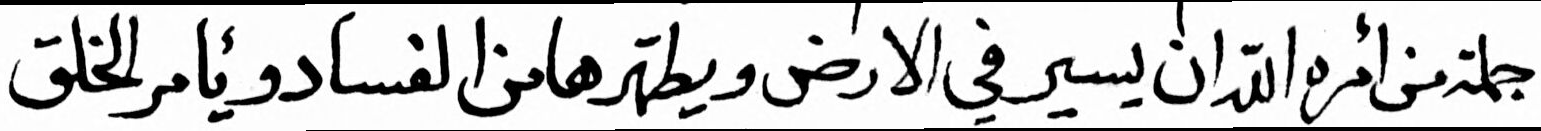
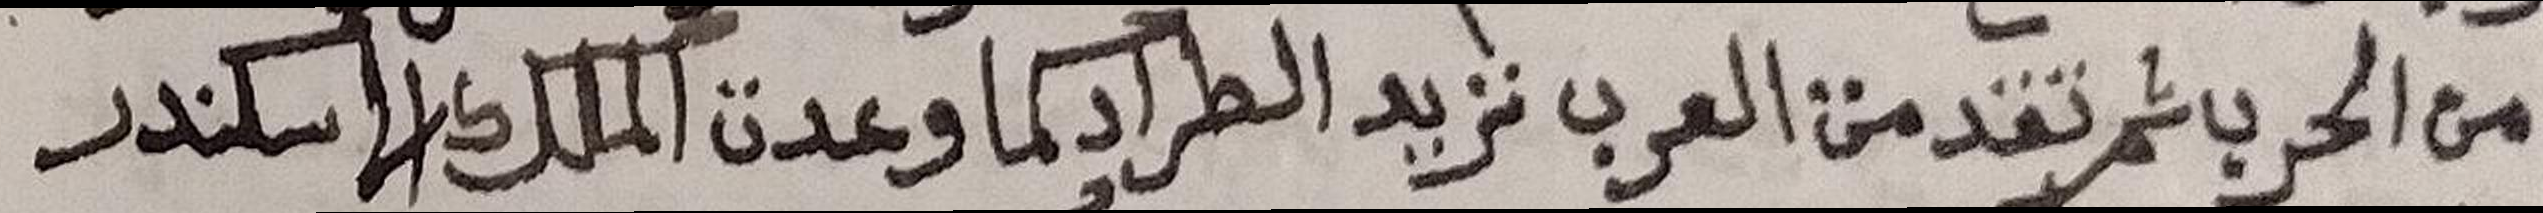

In [121]:
# Native-size source preview. Images are neither fitted to a grid nor resized.
if SHOW_CROP_PREVIEW and eligible:
    preview_pair=eligible[0]
    display_native_sources(preview_pair)
    print('Full source images shown at original pixel dimensions; horizontal scrolling preserves size.')
    print('Checkpoint input preprocessing:',EVALUATION_CROP)


## 2. SIMILARITY / MATCHING SETTINGS

Change the threshold **here only**. Do not rerun session setup or any sample-selection cell. Call `show_existing_sample(slot)` for the same sample at the new threshold.

The alignment mode, threshold and repeat controls change the pair alignment and accepted regions, **not** the frozen window embeddings. Repeated thresholds reuse cached matching results. A new threshold may require slower CPU alignment, but never reruns the CNN/Transformer.


In [ ]:
# FIXED WORD VOCABULARY — only available original lines in saved training IDs.
from word_alignment import normalize_word
from text_embedding import clean_letters
_counts, _books, _spaced, _hashes = Counter(), Counter(), Counter(), {}
for _record in session.views['train'].records:
    _side = _record['sides'][0]
    _text = Path(_side['text']).read_text(encoding='utf-8')
    _book = _record['book_id']
    _books[_book] += 1
    _hashes[_record['sample_id']] = hashlib.sha256(_text.encode()).hexdigest()
    if ' ' not in _text.strip():
        continue
    _spaced[_book] += 1
    for _value in _text.split():
        _word = normalize_word(''.join(clean_letters(_value)))
        if 2 <= len(_word) <= 12:
            _counts[_word] += 1
_words = {w: count for w, count in _counts.items() if count >= 2 and (len(w) > 2 or count >= 10)}
for _word, _count in list(_words.items()):
    if any(_word[:i] in _words and _word[i:] in _words and
           min(_words[_word[:i]], _words[_word[i:]]) >= 2 * _count for i in range(2, len(_word)-1)):
        del _words[_word]
if not _words:
    raise ValueError('No eligible training vocabulary in the available ArabicData2 subset')
_vocabulary = dict(schema_version=1, source_split='train', checkpoint_sha256=session.checkpoint_sha256,
    training_split_sha256=hashlib.sha256(json.dumps(session.saved['split_ids']['train'], sort_keys=True).encode()).hexdigest(),
    current_training_transcripts_sha256=hashlib.sha256(json.dumps(_hashes, sort_keys=True).encode()).hexdigest(),
    book_training_lines=dict(_books), training_lines_with_spaces=dict(_spaced), words=dict(sorted(_words.items())),
    available_training_ids=sorted(_hashes),
    limitation='Available saved-training original lines only; historical full training inventory is unavailable. No evaluated transcripts or masks enter the decoder.')
_vocabulary_path = project_path(RESULTS_ROOT) / 'vocabulary.json'
_vocabulary_path.parent.mkdir(parents=True, exist_ok=True)
_vocabulary_path.write_text(json.dumps(_vocabulary, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('Fixed available-training vocabulary:', len(_words), 'words from', len(_hashes), 'unique lines')

# EVALUATION-ONLY MATCHING SETTINGS. Rerun just this cell when tuning.
# Numerical settings copied from the source notebook; not recalibrated for ArabicData2.
# Original notebook preset (transferred unchanged): word_nll1.8_posterior0.075_short0.15_cos0.4.
# See the report at the top for the recall/false-positive trade-off.
from evaluate import resolved_match_settings

# ---- Decoder / similarity -------------------------------------------------
ALIGNMENT_MODE = 'local_repeat_dtw'  # "local_repeat_dtw" (default) | "affine" (Smith-Waterman) | "stretch"
CANDIDATE_SIMILARITY_MODE = 'letter_evidence'  # "cosine" | "letter_evidence" | "bidirectional_window"; overrides SIMILARITY_MODE
SIMILARITY_MODE = 'letter_evidence'  # same modes; candidate setting also selects rewards
# Image-only experiment: set BOTH similarity settings above to "bidirectional_window".
WINDOW_MATCH_TEMPERATURE = 0.1
WINDOW_MATCH_MIN_COSINE = 0.5
WINDOW_MATCH_REWARD_OFFSET = 0.0

SIMILARITY_THRESHOLD = 0.5  # float in [-1, 1]; higher = stricter window match
SCORE_MODE = 'background'  # "raw" | "background" (subtract background cosine level)
CONTRAST_MARGIN = 0.05  # float >= 0; extra margin a match must beat alternatives by

# ---- Independent passage extraction ---------------------------------------
ALLOW_REORDERED_REGIONS = True  # updated by the validation-selected preset
SPLIT_GAP_CANDIDATES = True  # retain gap-free fragments as extra candidates
REQUIRE_CORROBORATED_SHORT_REGIONS = True  # several short passages must jointly establish a match
NORMAL_MIN_MEAN_COSINE = 0.6  # optional visual-confidence floor for long regions

# ---- Normal (long) region acceptance -------------------------------------
NORMAL_MIN_DISTINCT_A = 9  # int >= 1; distinct windows required in line A
NORMAL_MIN_DISTINCT_B = 9  # int >= 1; distinct windows required in line B
NORMAL_MIN_MATCHED_PAIRS = 12  # int >= 1; matched (A,B) window pairs required

# ---- Short region acceptance (stricter evidence) -------------------------
ALLOW_SHORT_REGIONS = True  # True | False; False rejects every region below the normal minimums
SHORT_MIN_DISTINCT_A = 2  # int >= 1
SHORT_MIN_DISTINCT_B = 2  # int >= 1
SHORT_MIN_MATCHED_PAIRS = 4  # int >= 1
SHORT_MIN_MEAN_COSINE = 0.75  # float in [-1, 1]; mean path cosine
SHORT_MIN_MEDIAN_COSINE = 0.75  # float in [-1, 1]; median path cosine
SHORT_MIN_MEAN_REWARD = 0.25  # float; mean per-match reward
SHORT_MIN_PATH_DENSITY = 0.9  # float in [0, 1]; matched cells / path length
SHORT_MAX_INTERNAL_GAP = 0  # int >= 0; 0 = no gaps allowed inside short regions
SHORT_MIN_MUTUAL_ANCHORS = 2  # int >= 0; mutual top-k anchors required
SHORT_MIN_MUTUAL_ANCHOR_FRACTION = 0.4  # float in [0, 1]

# ---- Gaps and repeats -----------------------------------------------------
MAX_INTERNAL_GAP = 4  # int >= 0; max skipped windows inside a path
GAP_OPEN = 0.5940936607241908  # float >= 0; penalty to start a gap
GAP_EXTEND = 0.5826132317598225  # float >= 0; penalty per extra gap window
REPEAT_PENALTY = 0.2  # float >= 0; penalty per repeated window
MAX_CONSECUTIVE_REPEATS = 2  # int >= 1; max times one window repeats in a row

# ---- Anchor check ---------------------------------------------------------
USE_PATH_ANCHOR_CHECK = True  # True | False; verify paths with mutual top-k anchors
ANCHOR_TOP_K = 4  # int >= 1; k for the mutual top-k test
MIN_MUTUAL_ANCHORS_LONG = 7  # int >= 0; long regions
MIN_MUTUAL_ANCHOR_FRACTION_LONG = 0.05  # float in [0, 1]; long regions
MIN_MUTUAL_ANCHORS_SHORT = 2  # int >= 0; short regions
MIN_MUTUAL_ANCHOR_FRACTION_SHORT = 0.4  # float in [0, 1]; short regions

# ---- Path extension and merging ------------------------------------------
ENABLE_PATH_EXTENSION = False  # True | False; grow paths past weak ends
EXTENSION_MIN_REWARD = 0.0  # float; minimum reward to extend
EXTENSION_MAX_WEAK_RUN = 1  # int >= 0; max consecutive weak steps tolerated
EXTENSION_MAX_INTERNAL_GAP = 2  # int >= 0; max gap allowed while extending
ENABLE_REGION_MERGING = False  # True | False; merge neighbouring regions
MERGE_MAX_GAP_A = 1  # int >= 0; max window gap in A to merge
MERGE_MAX_GAP_B = 2  # int >= 0; max window gap in B to merge
DOMINANCE_MIN_QUALITY_RATIO = 0.75  # float in (0, 1]; lower-quality overlaps rejected below this ratio

# ---- Letter evidence and optional minimums (None = disabled) -------------
VERIFY_WITH_LETTER_EVIDENCE = False  # True | False; verify regions with letter evidence
MIN_MEAN_LETTER_EVIDENCE = None  # None | float
MIN_LETTER_POSITIVE_FRACTION = None  # None | float in [0, 1]
MIN_MEDIAN_BIDIRECTIONAL_MARGIN_LONG = None  # None | float
MIN_MEDIAN_BIDIRECTIONAL_MARGIN_SHORT = None  # None | float
MIN_REGION_SCORE = None  # None | float
MIN_MEAN_REWARD = 0.0  # None | float
MIN_PATH_DENSITY = 0.85  # None | float in [0, 1]
MAX_REPEAT_FRACTION = None  # None | float in [0, 1]
MIN_SECONDARY_SCORE_RATIO = None  # None | float in [0, 1]; secondary vs best region score

# ---- Limits and display ---------------------------------------------------
MAX_ALIGNMENT_CANDIDATES = 512  # int >= 1; pool capacity, not a confidence threshold
MAX_REJECTED_PATHS_TO_PLOT = 5                # int >= 0; rejected paths drawn per plot
MAX_STRETCH = 3  # int >= 1; legacy "stretch" decoder only
ACCEPTANCE_OFFSET = 0.1  # float; legacy decoder acceptance offset
PRIOR_FLOOR = 0.0001  # float > 0; floor for legacy prior probabilities
COMPARISON_MAX_PAIRS = 0                      # int >= 0; 0 = all pairs
CANDIDATES_TO_DISPLAY = 5                     # int >= 1; candidates shown in diagnostics
# ---- Image-only whole-word verification --------------------------------
WORD_VOCABULARY_PATH = str(_vocabulary_path)
WORD_MAX_NLL = 1.8
WORD_MIN_POSTERIOR = 0.075
WORD_MIN_POSTERIOR_SHORT = 0.15
WORD_MIN_COSINE = 0.4
WORD_BOUNDARY_WEIGHT = 2.0
WORD_LATTICE_TEMPERATURE = 1.0
WORD_KEEP_LONG_REGIONS = True
WORD_VISUAL_WEIGHT = 12.0
WORD_MIN_DISTINCT_TYPES = 2
WORD_MIN_TOTAL_CHARACTERS = 8


Fixed available-training vocabulary: 130 words from 116 unique lines


In [123]:
def current_match_settings(threshold=None):
    names = (
        "normal_min_distinct_a normal_min_distinct_b normal_min_matched_pairs "
        "normal_min_mean_cosine allow_reordered_regions split_gap_candidates require_corroborated_short_regions "
        "allow_short_regions short_min_distinct_a short_min_distinct_b short_min_matched_pairs "
        "short_min_mean_cosine short_min_median_cosine short_min_mean_reward short_min_path_density "
        "short_max_internal_gap short_min_mutual_anchors short_min_mutual_anchor_fraction "
        "use_path_anchor_check anchor_top_k min_mutual_anchors_long min_mutual_anchor_fraction_long "
        "min_mutual_anchors_short min_mutual_anchor_fraction_short enable_path_extension "
        "extension_min_reward extension_max_weak_run extension_max_internal_gap enable_region_merging "
        "merge_max_gap_a merge_max_gap_b dominance_min_quality_ratio verify_with_letter_evidence "
        "min_mean_letter_evidence min_letter_positive_fraction min_median_bidirectional_margin_long "
        "min_median_bidirectional_margin_short min_region_score min_mean_reward min_path_density "
        "max_repeat_fraction min_secondary_score_ratio "
        "window_match_temperature window_match_min_cosine window_match_reward_offset").split()
    names += 'word_vocabulary_path word_max_nll word_min_posterior word_min_posterior_short word_min_cosine word_boundary_weight word_lattice_temperature word_keep_long_regions word_visual_weight word_min_distinct_types word_min_total_characters'.split()
    adaptive = {name: globals()[name.upper()] for name in names}
    return resolved_match_settings(dict(adaptive,
        alignment_mode=ALIGNMENT_MODE, candidate_similarity_mode=CANDIDATE_SIMILARITY_MODE,
        similarity_mode=SIMILARITY_MODE,
        threshold=SIMILARITY_THRESHOLD if threshold is None else float(threshold),
        score_mode=SCORE_MODE, contrast_margin=CONTRAST_MARGIN,
        max_gap=MAX_INTERNAL_GAP, gap_open=GAP_OPEN, gap_extend=GAP_EXTEND,
        repeat_penalty=REPEAT_PENALTY, max_consecutive_repeats=MAX_CONSECUTIVE_REPEATS,
        max_candidates=MAX_ALIGNMENT_CANDIDATES, max_stretch=MAX_STRETCH,
        acceptance_offset=ACCEPTANCE_OFFSET, prior_floor=PRIOR_FLOOR))

# Refresh project code after edits without rebuilding the session or encoder.
# Reload dependencies first, then refresh any notebook imports (including aliases).
import importlib as _matching_importlib
for _matching_module_name in ("dtw", "word_alignment", "alignment_candidates", "alignment_overlays", "train", "evaluate", "evaluation_utils"):
    _matching_module = _matching_importlib.reload(
        _matching_importlib.import_module(_matching_module_name))
    for _matching_name, _matching_value in list(globals().items()):
        if getattr(_matching_value, "__module__", None) == _matching_module_name:
            _matching_replacement = getattr(
                _matching_module, getattr(_matching_value, "__name__", ""), None)
            if _matching_replacement is not None:
                globals()[_matching_name] = _matching_replacement
from evaluate import resolved_match_settings, MATCH_VERSION
# Sessions created before lazy character loading kept this state under text_encoder.
if not hasattr(session, "_text_encoder"):
    session._text_encoder = session.__dict__.get("text_encoder")

SETTINGS = current_match_settings()
session.settings = dict(SETTINGS)
# A–B confidence was calibrated separately. C keeps its existing base settings.
# Transfer the exact original confidence values as requested. Keep their source
# provenance; the original preset was calibrated for a different checkpoint.
from evaluation_presets import CONFIDENCE_KEYS
_source_preset = (json.loads(project_path(AB_CONFIDENCE_PRESET).read_text())
                  if AB_CONFIDENCE_PRESET else None)
PAIR_MATCH_OVERRIDES = ({'A_B': {key: _source_preset['settings'][key] for key in CONFIDENCE_KEYS}}
                        if _source_preset else {})
print('Original confidence values transferred unchanged; not calibrated for these ArabicData2 weights.')

def current_ab_match_settings(threshold=None):
    return resolved_match_settings(dict(current_match_settings(threshold), **PAIR_MATCH_OVERRIDES.get('A_B', {})))

print('Transferred A–B confidence values (ArabicData2 has only A/B):')
display(pd.DataFrame([PAIR_MATCH_OVERRIDES.get('A_B', {})]))
DECODER = SETTINGS['decoder']

_hidden = ("use_strong_start_anchor", "start_top_k", "start_min_reward")
_groups = (
    ("Whole-word verification", 'word_vocabulary_path word_max_nll word_min_posterior word_min_posterior_short word_min_cosine word_boundary_weight word_lattice_temperature word_keep_long_regions word_visual_weight word_min_distinct_types word_min_total_characters'),
    ("Decoder / similarity", "similarity_mode decoder alignment_mode candidate_similarity_mode threshold score_mode contrast_margin"),
    ("Window experiment", "window_match_temperature window_match_min_cosine window_match_reward_offset"),
    ("Independent passages", "allow_reordered_regions split_gap_candidates require_corroborated_short_regions normal_min_mean_cosine"),
    ("Normal regions", "normal_min_distinct_a normal_min_distinct_b normal_min_matched_pairs min_windows min_distinct_windows_a min_distinct_windows_b min_matched_pairs"),
    ("Short regions", "allow_short_regions short_min_distinct_a short_min_distinct_b short_min_matched_pairs short_min_mean_cosine short_min_median_cosine short_min_mean_reward short_min_path_density short_max_internal_gap short_min_mutual_anchors short_min_mutual_anchor_fraction"),
    ("Gaps / repeats", "max_gap gap_open gap_extend repeat_penalty max_consecutive_repeats"),
    ("Anchors", "use_path_anchor_check anchor_top_k min_mutual_anchors_long min_mutual_anchor_fraction_long min_mutual_anchors_short min_mutual_anchor_fraction_short"),
    ("Extension / merging", "enable_path_extension extension_min_reward extension_max_weak_run extension_max_internal_gap enable_region_merging merge_max_gap_a merge_max_gap_b dominance_min_quality_ratio"),
    ("Letter evidence", "verify_with_letter_evidence min_mean_letter_evidence min_letter_positive_fraction min_median_bidirectional_margin_long min_median_bidirectional_margin_short"),
    ("Optional minimums", "min_region_score min_mean_reward min_path_density max_repeat_fraction min_secondary_score_ratio"),
    ("Limits / legacy", "max_candidates max_stretch acceptance_offset prior_floor"),
)
_group_of = {name: group for group, names in _groups for name in names.split()}
_rows = [(_group_of.get(name, "Other"), name, "None (disabled)" if value is None else value)
         for name, value in SETTINGS.items() if name not in _hidden]
_order = [g for g, _ in _groups] + ["Other"]
_rows.sort(key=lambda r: _order.index(r[0]))
_table = pd.DataFrame(_rows, columns=["Group", "Parameter", "Value"]).set_index(["Group", "Parameter"])
print("Active evaluator configuration (original values transferred to ArabicData2):")
display(_table)
print("Whole-path anchors replace the first-cell rule. Short regions use stronger evidence.")

def image_only_window_mode():
    return current_match_settings()["similarity_mode"] == "bidirectional_window"


Original confidence values transferred unchanged; not calibrated for these ArabicData2 weights.
Transferred A–B confidence values (ArabicData2 has only A/B):


,word_max_nll,word_min_posterior,word_min_posterior_short,word_min_cosine,word_min_distinct_types,word_min_total_characters,word_visual_weight,word_strong_pair_max_nll,word_strong_pair_min_cosine
0,1.6,0.075,0.25,0.6,3,10,12.0,0.55,0.75


Active evaluator configuration (original values transferred to ArabicData2):


Value
Group                   Parameter                                                                     
Whole-word verification word_vocabulary_path         /Users/ahmedmas/Desktop/AlignmentProject/Resul...
                        word_max_nll                                                               1.8
                        word_min_posterior                                                       0.075
                        word_min_posterior_short                                                  0.15
                        word_min_cosine                                                            0.4
...                                                                                                ...
Limits / legacy         max_stretch                                                                  3
                        acceptance_offset                                                          0.1
                        prior_floor                                                             0.0001
Other                   word_strong_pair_max_nll                                       None (disabled)
                        word_strong_pair_min_cosine                                               0.75

[78 rows x 1 columns]

Whole-path anchors replace the first-cell rule. Short regions use stronger evidence.


### Optional image-only bidirectional window experiment

In the settings cell above use:
```python
CANDIDATE_SIMILARITY_MODE = "bidirectional_window"
SIMILARITY_MODE = "bidirectional_window"
WINDOW_MATCH_TEMPERATURE = 0.10
WINDOW_MATCH_MIN_COSINE = 0.50
WINDOW_MATCH_REWARD_OFFSET = 0.0
VERIFY_WITH_LETTER_EVIDENCE = False
```
Keep ALIGNMENT_MODE="local_repeat_dtw". Rerun settings and an existing sample representation; compatible cached image embeddings remain available. These are initial experimental values, not optimal settings. Existing notebook defaults are retained, including candidate_similarity_mode overriding similarity_mode for cosine/letter_evidence. There is one reward mode per run; conflicting combinations involving bidirectional_window are rejected.

For N and M valid windows, C is float32 normalized image-window cosine. Evidence = 0.5 * (log_softmax(C/T, axis=1) + log(M) + log_softmax(C/T, axis=0) + log(N)); reward = evidence - offset. Padding is excluded first. Directional scores are normalized relative scores, not calibrated match probabilities. Unrelated pairs can have strong relative best matches, and repeated valid windows compete for mass. The absolute cosine gate does not solve every negative-pair false positive.

Below-gate cells cannot be matched or anchors; the existing gap rules can skip them. Existing mask projection is unchanged: overlapping window footprints and allowed small internal fills can render foreground across an unmatched/gated window. A foreground pixel is not proof of a matched window pair. Extension also retains its existing SIMILARITY_THRESHOLD requirement, which can be stricter than the absolute gate.

Sample outputs include raw cosine, evidence, reward, eligibility, accepted/rejected routes, predicted masks and existing metrics. Letter recognition, transcript ranking and the window-letter inspector are skipped in this mode.


In [124]:
# Small diagnostics only: no checkpoint, encoder, transcripts or training.
RUN_WINDOW_DIAGNOSTIC_EXAMPLES = False
if RUN_WINDOW_DIAGNOSTIC_EXAMPLES:
    from evaluate import window_match_diagnostic_examples, plot_window_match_diagnostics
    for name, match in window_match_diagnostic_examples().items():
        print(name, "accepted regions:", len(match["regions"]),
              "eligible cells:", int(match["absolute_cosine_eligible"].sum()))
        fig = plot_window_match_diagnostics(match)
        display(fig); plt.close(fig)


<a id="book-pair-samples"></a>
## Selected alignment review

These review slots are retained. ArabicData2 has two books and no supplied masks or saved review figures.


In [125]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


### A–B — fixed review slots

Use the independent sample cells below to generate ArabicData2 examples.


In [126]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [127]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [128]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [129]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [130]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


### A–C — fixed review slots

ArabicData2 has no Book C; these slots are unavailable.


In [131]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [132]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [133]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [134]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [135]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


### B–C — fixed review slots

ArabicData2 has no Book C; these slots are unavailable.


In [136]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [137]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [138]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [139]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


In [140]:
# Original review cell retained for ArabicData2.
print("No corresponding saved ArabicData2 review figure; run the sample cells below.")


No corresponding saved ArabicData2 review figure; run the sample cells below.


## 3. Random positive-pair pool — execute once

Each sample group has one **Select pair** cell followed by LOCAL, FUSED, and CONTEXT
output cells. Rerunning Select pair chooses a new recorded aligned pair only for that
slot; representation cells reuse its saved pair. A seeded shuffled queue supplies each
eligible pair once. When exhausted, existing slots stay unchanged.


In [141]:
pool = shuffled_positive_pairs(session, seed=RANDOM_SEED,
                               require_ground_truth=REQUIRE_GROUND_TRUTH)
_sample_rng = random.Random(RANDOM_SEED)
_remaining_pairs = []
sample_slots = {}         # slot -> manifest pair, threshold-independent base and GT
base_cache = {}           # (sample id, representation) -> cached features/cosine
match_cache = {}          # exact evaluation key -> threshold-dependent result
recognitions = {}        # optional window-letter diagnostics

# Deduplicate after GT eligibility, retaining deterministic sample order.
pool = list({pair["sample_id"]: pair for pair in pool}.values())
_remaining_pairs.extend(pool)
_sample_rng.shuffle(_remaining_pairs)

def next_positive_pair(exclude_id=None):
    shown = {sample["pair"]["sample_id"] for sample in sample_slots.values()}
    while _remaining_pairs:
        pair = _remaining_pairs.pop()
        if pair["sample_id"] not in shown and pair["sample_id"] != exclude_id:
            return pair
    return None

print(f"CSV partner pool: {len(pool)} pair(s), saved split={session.split}.")
requested_positive_count = globals().get("N_POSITIVE_SAMPLES", NUM_SAMPLES)
if requested_positive_count > len(pool):
    print(f"Requested {requested_positive_count} unique positive samples, "
          f"but only {len(pool)} eligible unique samples are available.")
print("Each Select pair cell chooses both lines from ONE recorded positive pair.")


CSV partner pool: 2 pair(s), saved split=test.
Requested 10 unique positive samples, but only 2 eligible unique samples are available.
Each Select pair cell chooses both lines from ONE recorded positive pair.


## 4. Independent sample cells

For each Sample N, run **Select pair** once. Then run its three consecutive output cells:
**LOCAL**, **FUSED**, **CONTEXT**. Each cell shows only that representation's full
images, heatmaps, routes, masks, and metrics for the same saved A/B pair.

Rerunning a representation cell keeps the sample unchanged. Rerun **Select pair**
only when you want a different sample, then rerun the three output cells.
`N_POSITIVE_SAMPLES` controls how many sample groups run on Run All.

Set `SHOW_REPRESENTATIONS` in the setup cell (e.g. `["fused"]`, `["local", "context"]`, or `"all"`) to choose
which representations are displayed; cells for hidden ones print a short note and do nothing.


In [142]:
KEY_METRICS = [
    "pair_score", "path_cosine_mean", "path_cosine_median", "path_cosine_min",
    "maximum_similarity", "off_path_cosine_mean", "similarity_separation",
    "path_length", "region_count", "matched_windows_a", "matched_windows_b",
    "total_windows_a", "total_windows_b", "mask_coverage_a", "mask_coverage_b",

]

from evaluation_utils import REPRESENTATIONS, predict_cached_pair, print_candidate_diagnostics
from evaluation_presets import settings_for_pair
from evaluate import resolved_match_settings, MATCH_VERSION
import json

def infer_positive_pair_base(session, pair, representation):
    """Stop after cached model features and raw pair cosine; no matcher or masks."""
    if pair["target"] != 1 or pair["constructed_negative"]:
        raise ValueError("Expected one recorded CSV partner pair")
    if representation not in ("local", "context", "fused"):
        raise ValueError("Unknown representation")
    key = (pair["sample_id"], representation)
    if key in base_cache:
        return base_cache[key], 0.0, 0.0, 0
    before = len(session.feature_cache)
    started = time.perf_counter()
    lines = [session.get_line_features(side) for side in pair["sides"]]
    feature_seconds = time.perf_counter() - started
    started = time.perf_counter()
    cosine = cosine_similarity_matrix(
        lines[0]["features"][representation],
        lines[1]["features"][representation]).numpy()
    assert np.isfinite(cosine).all()
    base = dict(pair=pair, lines=lines, cosine=cosine,
                representation=representation, split=session.split)
    base_cache[key] = base
    return base, feature_seconds, time.perf_counter() - started, len(session.feature_cache) - before

def _match_key(base, settings):
    return (base["pair"]["sample_id"], base["representation"], MATCH_VERSION,
            session.checkpoint_sha256, json.dumps(resolved_match_settings(settings), sort_keys=True))

def _rescore_cached(sample, settings, base=None):
    """Shared prediction on cached features; describe routes without GT scoring."""
    base = sample["base"] if base is None else base
    result = predict_cached_pair(session, base["pair"], base["lines"],
        base["representation"], settings=settings, cosine=base["cosine"])
    return describe_prediction(result, session.config)



def evaluate_cached_sample(slot, threshold=None, *, representation=None, **matching_overrides):
    """No model, feature lookup, annotation file load or sample selection."""
    if slot not in sample_slots:
        raise ValueError(f"Sample slot {slot} is empty: run its random-sample cell first.")
    sample = sample_slots[slot]
    rep = representation or sample["base"]["representation"]
    if rep not in REPRESENTATIONS:
        raise ValueError(f"Unknown representation: {rep}")
    bases = sample.setdefault("bases", {sample["base"]["representation"]: sample["base"]})
    if rep not in bases:
        # Also supports slots selected before this helper cell was refreshed.
        lines = sample["base"]["lines"]
        bases[rep] = dict(sample["base"], representation=rep, cosine=cosine_similarity_matrix(
            lines[0]["features"][rep], lines[1]["features"][rep]).numpy())
    base = bases[rep]
    settings = settings_for_pair(base["pair"], current_match_settings(threshold), globals().get("PAIR_MATCH_OVERRIDES", {}))
    unknown = set(matching_overrides) - set(settings)
    if unknown:
        raise ValueError(f"Unknown matching override(s): {sorted(unknown)}")
    settings.update(matching_overrides)
    settings = resolved_match_settings(settings)
    key = _match_key(base, settings)
    before = len(session.feature_cache)
    started = time.perf_counter()
    if key in match_cache:
        result = match_cache[key]
        sample["ground_truth"] = result["ground_truth"]
        sample["gt_provenance"] = result["metrics"].get("ground_truth_provenance")
        sample["matching_seconds"] = 0.0
        print("Reusing cached threshold evaluation. No CNN/Transformer inference performed.")
    else:
        result = _rescore_cached(sample, settings, base=base)
        match_cache[key] = result
        sample["matching_seconds"] = time.perf_counter() - started
        print(f"Matching on cached cosine: {sample['matching_seconds']:.2f} s. "
              "No CNN/Transformer inference performed.")
    assert len(session.feature_cache) == before, "Threshold evaluation changed the feature cache"
    sample.setdefault("results", {})[rep] = result
    return result

def _display_sample_result(slot, result):
    sample = sample_slots[slot]
    if result["representation"] == sample["base"]["representation"]:
        sample["result"] = result
    pair = sample["pair"]
    print(f"{result['representation'].upper()} | Sample slot {slot} | pair={pair['sample_id']} | "
          f"threshold={result['settings']['threshold']:.3f} | split={session.split}")
    print_candidate_diagnostics(result, MAX_REJECTED_PATHS_TO_PLOT)
    plotter = plot_qualitative_alignment
    fig = plotter(session, result, show_gt=globals().get("SHOW_GT_MASKS", False), show_input_crop=True)
    display(fig)
    plt.close(fig)
    if result["settings"]["similarity_mode"] == "bidirectional_window":
        from evaluate import plot_window_match_diagnostics
        fig = plot_window_match_diagnostics(result["match"], MAX_REJECTED_PATHS_TO_PLOT)
        display(fig); plt.close(fig)
        print("Directional softmax scores and evidence are relative, uncalibrated matching evidence.")
    metrics = result["metrics"]
    display(pd.Series({name: metrics.get(name) for name in KEY_METRICS
                       if metrics.get(name) is not None}, name=pair["sample_id"]))
    print("Rejected reasons:", dict(Counter(x["reason"]
          for x in result["match"]["rejected"])))
    return result

def _display_sample_representations(slot, results):
    """One cell output: LOCAL, then CONTEXT, then FUSED for the same pair."""
    sample = sample_slots[slot]
    pair_id = sample["pair"]["sample_id"]
    assert all(result["pair"]["sample_id"] == pair_id for result in results.values())
    assert len({json.dumps(result["settings"], sort_keys=True) for result in results.values()}) == 1
    print(f"Same pair in selected representations ({', '.join(r.upper() for r in SHOWN_REPRESENTATIONS)}): {pair_id}")
    for rep in SHOWN_REPRESENTATIONS:
        print(f"\n===== {rep.upper()} — {pair_id} =====")
        _display_sample_result(slot, results[rep])
    comparison = pd.DataFrame({rep.upper(): {
        name: results[rep]["metrics"].get(name) for name in KEY_METRICS}
        for rep in SHOWN_REPRESENTATIONS})
    print("Same-sample metric comparison")
    display(comparison.rename_axis("metric"))
    return results


def show_existing_sample(slot, threshold=None):
    """Display all representations of the same saved pair, without selecting another."""
    results = {rep: evaluate_cached_sample(slot, threshold, representation=rep)
               for rep in SHOWN_REPRESENTATIONS}
    return _display_sample_representations(slot, results)

def show_random_sample(slot, *, display_results=True):
    """Replace only this slot with a newly drawn recorded CSV partner pair."""
    if not isinstance(slot, int) or slot < 1:
        raise ValueError("Sample slot must be a positive integer")
    if not pool:
        print("No eligible positive pairs.")
        return None
    previous_id = sample_slots[slot]["pair"]["sample_id"] if slot in sample_slots else None
    for _ in range(len(pool)):
        pair = next_positive_pair(exclude_id=previous_id)
        if pair is None:
            print("No unused unique positive sample remains; no duplicate will be displayed.")
            return None
        bases = {}
        inference_seconds, cosine_seconds, new_lines = 0.0, 0.0, 0
        for rep in REPRESENTATIONS:
            base, feature_time, cosine_time, added = infer_positive_pair_base(session, pair, rep)
            bases[rep] = base
            inference_seconds += feature_time
            cosine_seconds += cosine_time
            new_lines += added
        # Keep the primary representation for optional population/tuning/saving tools.
        sample = dict(pair=pair, base=bases[REPRESENTATION], bases=bases, results={}, result=None)
        previous = sample_slots.get(slot)
        sample_slots[slot] = sample
        try:
            results = {}
            matching_seconds = 0.0
            for rep in SHOWN_REPRESENTATIONS:
                results[rep] = evaluate_cached_sample(slot, representation=rep)
                matching_seconds += sample["matching_seconds"]
        except Exception:
            if previous is None: sample_slots.pop(slot, None)
            else: sample_slots[slot] = previous
            raise
        print(f"Sample inference: feature retrieval {inference_seconds:.2f}s ({new_lines} new lines); "
              f"cosine {cosine_seconds:.2f}s; representation prediction/diagnostics {matching_seconds:.2f}s")
        if display_results:
            return _display_sample_representations(slot, results)
        print(f"Selected sample slot {slot}: {pair['sample_id']}. Run the representation cells below.")
        return results
    print("No usable NEW positive pair found; existing slot remains unchanged.")
    return None

def select_random_sample(slot):
    """Select once; the three following output cells reuse this saved slot."""
    return show_random_sample(slot, display_results=False)


def show_sample_representation(slot, representation):
    """Display one representation of an already selected pair; never draw a pair."""
    if representation not in SHOWN_REPRESENTATIONS:
        print(f"{representation.upper()} hidden by SHOW_REPRESENTATIONS = {SHOW_REPRESENTATIONS!r}.")
        return None
    if slot not in sample_slots:
        print(f"Sample {slot} unavailable in the selected split; no pair has been selected.")
        return None
    result = evaluate_cached_sample(slot, representation=representation)
    return _display_sample_result(slot, result)


def show_random_samples(n):
    """Optional manual convenience; Run All calls individual sample cells."""
    if n < 1:
        raise ValueError("n must be >= 1")
    return [show_random_sample(slot) for slot in range(1, n + 1)]


### Refresh window-color overlays

Run the cell below to reload plotting code and redraw a cached sample. Each masked window gets its own color, shared with all its matched windows in the other line. Repeat matches form a single color group. Overlapping windows are divided at their nearest centers so colors stay distinct. No model inference or new sample selection is needed. Change `OVERLAY_SAMPLE_SLOT` to inspect another saved sample. Previously rendered figures update when you rerun their cells.


In [143]:
# REFRESH WINDOW-COLOR OVERLAYS — run this on an already selected sample.
# Reloads plotting only; keeps the selected pair, features, masks and scores.
OVERLAY_SAMPLE_SLOT = 1
OVERLAY_REPRESENTATION = "fused"

import importlib as _overlay_importlib
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
for _overlay_module_name in ("alignment_overlays", "evaluation_utils"):
    _overlay_importlib.reload(_overlay_importlib.import_module(_overlay_module_name))
from alignment_overlays import aligned_window_overlays
from evaluation_utils import plot_pair_alignment, save_pair_artifacts, set_line_window_axis


def refresh_window_color_overlays(slot=1, representation="fused"):
    sample = globals().get("sample_slots", {}).get(slot)
    if sample is None:
        print(f"Select Sample {slot} and run its {representation.upper()} cell first, then rerun this cell.")
        return None
    result = sample.get("results", {}).get(representation)
    if result is None:
        existing = sample.get("result")
        if existing is not None and existing.get("representation") == representation:
            result = existing
    if result is None:
        print(f"Run Sample {slot} — {representation.upper()} first, then rerun this cell.")
        return None
    originals = []
    for side in result["pair"]["sides"]:
        with Image.open(side["image"]) as image:
            originals.append(image.convert("RGB"))
    overlays = aligned_window_overlays(
        originals, result["masks"], result["match"]["regions"],
        [line["physical"] for line in result["lines"]],
        [line["geometry"] for line in result["lines"]],
        session.config.window_width, session.config.window_stride)
    display(HTML(''.join(native_image_html(Image.fromarray(overlay),
        f'Line {name} — refreshed window-color overlay')
        for name,overlay in zip(('A','B'),overlays))))
    print("Refreshed window colors from cached predictions. Repeat matches share a color; overlapping windows use the nearest center.")
    print("The regular sample plots now use this color code too; rerun their representation cells.")
    return overlays


refreshed_window_overlays = refresh_window_color_overlays(OVERLAY_SAMPLE_SLOT, OVERLAY_REPRESENTATION)


Select Sample 1 and run its FUSED cell first, then rerun this cell.


### Sample 1 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 1; rerunning an output cell never selects another pair.


In [144]:
# Sample 1 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 1:
    select_random_sample(1);


Matching on cached cosine: 15.29 s. No CNN/Transformer inference performed.
Sample inference: feature retrieval 0.00s (0 new lines); cosine 0.01s; representation prediction/diagnostics 15.29s
Selected sample slot 1: ArabicData2:csv:331. Run the representation cells below.


In [145]:
# Sample 1 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 1:
    show_sample_representation(1, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [146]:
# Sample 1 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 1:
    show_sample_representation(1, "fused");


Reusing cached threshold evaluation. No CNN/Transformer inference performed.
FUSED | Sample slot 1 | pair=ArabicData2:csv:331 | threshold=0.500 | split=test
Sample: ArabicData2:csv:331 | label: stored_aligned_pair
GT available: [False, False]
Similarity matrix: 63 × 63
Accepted regions: 0
Evaluation category: qualitative (unannotated)
Rejected candidate 0:
  candidate_id: W5836
  candidate_type: word
  status: rejected_visual_candidate
  score: 8.855267402529716
  score_per_match: 0.8855267402529716
  matching_reward: 10.655267402529716
  word: الا
  word_nll: [1.2427026242762804, 1.235028657451272]
  word_posteriors: [0.005283266315784809, 0.003100395513260806]
  word_pair_posterior: 0.004047247852655081
  word_selection_score: 1.6264841639459817
  gap_penalty: 0.0
  repeat_penalty: 1.8
  support_a: 4
  support_b: 10
  matched_pairs: 10
  required_support_a: None
  required_support_b: None
  required_matched_pairs: None
  mean_cosine: 0.5946835279464722
  median_cosine: 0.685384452342

pair_score               0.000000
maximum_similarity       0.893147
off_path_cosine_mean     0.264975
path_length              0.000000
region_count             0.000000
matched_windows_a        0.000000
matched_windows_b        0.000000
total_windows_a         63.000000
total_windows_b         63.000000
mask_coverage_a          0.000000
mask_coverage_b          0.000000
Name: ArabicData2:csv:331, dtype: float64

Rejected reasons: {'word_lexical_cost': 34956, 'word_context_evidence': 4692, 'word_visual_sequence': 1}


Image display updated to original pixel dimensions; rerun this cell to refresh its images.


In [147]:
# Sample 1 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 1:
    show_sample_representation(1, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 2 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 2; rerunning an output cell never selects another pair.


In [148]:
# Sample 2 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 2:
    select_random_sample(2);


Matching on cached cosine: 10.79 s. No CNN/Transformer inference performed.
Sample inference: feature retrieval 2.27s (2 new lines); cosine 0.01s; representation prediction/diagnostics 10.79s
Selected sample slot 2: ArabicData2:csv:482. Run the representation cells below.


In [149]:
# Sample 2 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 2:
    show_sample_representation(2, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


Reusing cached threshold evaluation. No CNN/Transformer inference performed.
FUSED | Sample slot 2 | pair=ArabicData2:csv:482 | threshold=0.500 | split=test
Sample: ArabicData2:csv:482 | label: stored_aligned_pair
GT available: [False, False]
Similarity matrix: 63 × 63
Accepted regions: 1
Evaluation category: qualitative (unannotated)
Region 0:
  candidate_id: P0
  candidate_type: visual_passage
  status: accepted_alignment_candidate
  score: 32.97033237149243
  score_per_match: 0.7850079136069626
  matching_reward: 43.10045304894447
  word: None
  word_nll: None
  word_posteriors: None
  word_pair_posterior: None
  word_selection_score: None
  gap_penalty: 3.5301206774520395
  repeat_penalty: 6.600000000000003
  support_a: 27
  support_b: 29
  matched_pairs: 42
  required_support_a: 9
  required_support_b: 9
  required_matched_pairs: 12
  mean_cosine: 0.6075810115961802
  median_cosine: 0.6243992447853088
  min_cosine: 0.15753698348999023
  mean_reward: 1.0262012630701065
  median_rew

pair_score               32.970332
path_cosine_mean          0.607581
path_cosine_median        0.624399
path_cosine_min           0.157537
maximum_similarity        0.913248
off_path_cosine_mean      0.291653
similarity_separation     0.315928
path_length              42.000000
region_count              1.000000
matched_windows_a        27.000000
matched_windows_b        29.000000
total_windows_a          63.000000
total_windows_b          63.000000
mask_coverage_a           0.469707
mask_coverage_b           0.531923
Name: ArabicData2:csv:482, dtype: float64

Rejected reasons: {'word_lexical_cost': 28523, 'word_context_evidence': 7914, 'word_visual_sequence': 3, 'word_reuses_span': 8}


Image display updated to original pixel dimensions; rerun this cell to refresh its images.


"R1 / Line ASource x: [665, 1355)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 690 × 138 pxOriginal-resolution region crop — 690 × 138 px","R1 / Line BSource x: [704, 2037)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 1333 × 218 pxOriginal-resolution region crop — 1333 × 218 px"

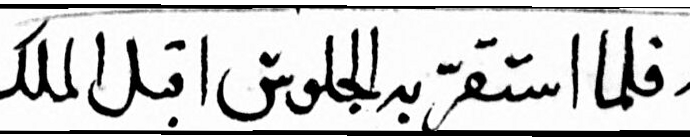
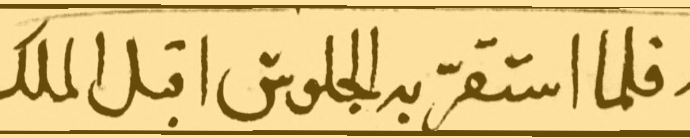
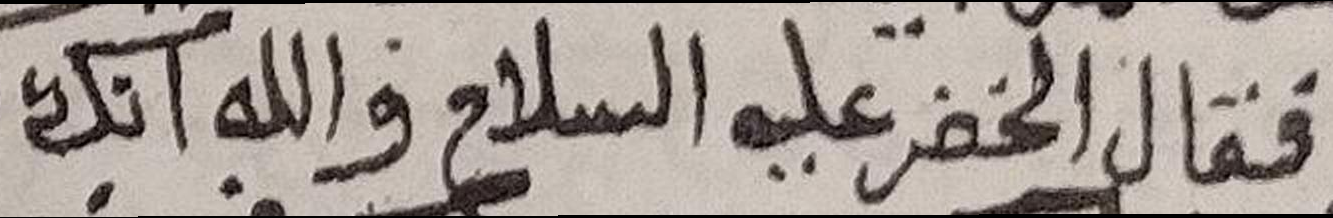
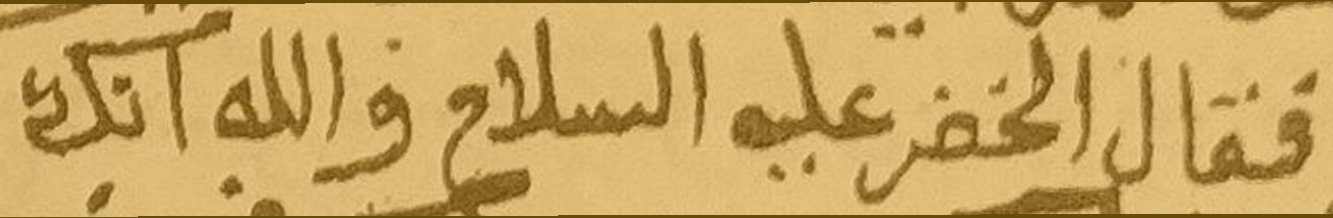

In [150]:
# Sample 2 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 2:
    show_sample_representation(2, "fused");


In [151]:
# Sample 2 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 2:
    show_sample_representation(2, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 3 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 3; rerunning an output cell never selects another pair.


In [152]:
# Sample 3 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 3:
    select_random_sample(3);


No unused unique positive sample remains; no duplicate will be displayed.


In [153]:
# Sample 3 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 3:
    show_sample_representation(3, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [154]:
# Sample 3 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 3:
    show_sample_representation(3, "fused");


Sample 3 unavailable in the selected split; no pair has been selected.


In [155]:
# Sample 3 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 3:
    show_sample_representation(3, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 4 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 4; rerunning an output cell never selects another pair.


In [156]:
# Sample 4 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 4:
    select_random_sample(4);


No unused unique positive sample remains; no duplicate will be displayed.


In [157]:
# Sample 4 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 4:
    show_sample_representation(4, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [158]:
# Sample 4 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 4:
    show_sample_representation(4, "fused");


Sample 4 unavailable in the selected split; no pair has been selected.


In [159]:
# Sample 4 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 4:
    show_sample_representation(4, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 5 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 5; rerunning an output cell never selects another pair.


In [160]:
# Sample 5 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 5:
    select_random_sample(5);


No unused unique positive sample remains; no duplicate will be displayed.


In [161]:
# Sample 5 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 5:
    show_sample_representation(5, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [162]:
# Sample 5 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 5:
    show_sample_representation(5, "fused");


Sample 5 unavailable in the selected split; no pair has been selected.


In [163]:
# Sample 5 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 5:
    show_sample_representation(5, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 6 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 6; rerunning an output cell never selects another pair.


In [164]:
# Sample 6 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 6:
    select_random_sample(6);


No unused unique positive sample remains; no duplicate will be displayed.


In [165]:
# Sample 6 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 6:
    show_sample_representation(6, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [166]:
# Sample 6 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 6:
    show_sample_representation(6, "fused");


Sample 6 unavailable in the selected split; no pair has been selected.


In [167]:
# Sample 6 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 6:
    show_sample_representation(6, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 7 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 7; rerunning an output cell never selects another pair.


In [168]:
# Sample 7 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 7:
    select_random_sample(7);


No unused unique positive sample remains; no duplicate will be displayed.


In [169]:
# Sample 7 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 7:
    show_sample_representation(7, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [170]:
# Sample 7 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 7:
    show_sample_representation(7, "fused");


Sample 7 unavailable in the selected split; no pair has been selected.


In [171]:
# Sample 7 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 7:
    show_sample_representation(7, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 8 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 8; rerunning an output cell never selects another pair.


In [172]:
# Sample 8 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 8:
    select_random_sample(8);


No unused unique positive sample remains; no duplicate will be displayed.


In [173]:
# Sample 8 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 8:
    show_sample_representation(8, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [174]:
# Sample 8 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 8:
    show_sample_representation(8, "fused");


Sample 8 unavailable in the selected split; no pair has been selected.


In [175]:
# Sample 8 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 8:
    show_sample_representation(8, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 9 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 9; rerunning an output cell never selects another pair.


In [176]:
# Sample 9 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 9:
    select_random_sample(9);


No unused unique positive sample remains; no duplicate will be displayed.


In [177]:
# Sample 9 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 9:
    show_sample_representation(9, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [178]:
# Sample 9 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 9:
    show_sample_representation(9, "fused");


Sample 9 unavailable in the selected split; no pair has been selected.


In [179]:
# Sample 9 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 9:
    show_sample_representation(9, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Sample 10 — select once, three representation cells

Run **Select pair** once, then **LOCAL → FUSED → CONTEXT** below.
All three cells use sample slot 10; rerunning an output cell never selects another pair.


In [180]:
# Sample 10 — Select pair (rerun only to choose a different pair).
if N_POSITIVE_SAMPLES >= 10:
    select_random_sample(10);


No unused unique positive sample remains; no duplicate will be displayed.


In [181]:
# Sample 10 — LOCAL: the same pair selected above.
if N_POSITIVE_SAMPLES >= 10:
    show_sample_representation(10, "local");


LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [182]:
# Sample 10 — FUSED: the same pair selected above.
if N_POSITIVE_SAMPLES >= 10:
    show_sample_representation(10, "fused");


Sample 10 unavailable in the selected split; no pair has been selected.


In [183]:
# Sample 10 — CONTEXT: the same pair selected above.
if N_POSITIVE_SAMPLES >= 10:
    show_sample_representation(10, "context");


CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


## 5. Qualitative review of presumed non-partners

Show seeded cross-book comparisons that exclude recorded partners, identical
images and shared normalized words. These are presumed negatives for inspection.
Review predicted regions and heatmaps visually; no correctness or mask score is calculated.


Presumed non-partner comparison samples: 10
Same unaligned comparison pair in all representations: ArabicData2:negative:BookA:429:BookB:485

===== FUSED — ArabicData2:negative:BookA:429:BookB:485 =====
Sample: ArabicData2:negative:BookA:429:BookB:485 | label: unmatched_lines_presumed_negative
GT available: [False, False]
Similarity matrix: 63 × 63
Accepted regions: 1
Evaluation category: qualitative (unannotated)
Region 0:
  candidate_id: P0
  candidate_type: visual_passage
  status: accepted_alignment_candidate
  score: 22.653551128732992
  score_per_match: 0.7307597138300965
  matching_reward: 30.618113093078136
  word: None
  word_nll: None
  word_posteriors: None
  word_pair_posterior: None
  word_selection_score: None
  gap_penalty: 3.564561964345145
  repeat_penalty: 4.4
  support_a: 26
  support_b: 18
  matched_pairs: 31
  required_support_a: 9
  required_support_b: 9
  required_matched_pairs: 12
  mean_cosine: 0.6083710780066829
  median_cosine: 0.6011620759963989
  min_cosine:

,FUSED
metric,
pair_score,22.653551
path_cosine_mean,0.608371
path_cosine_median,0.601162
path_cosine_min,0.316631
maximum_similarity,0.918604
off_path_cosine_mean,0.294845
similarity_separation,0.313526
path_length,31.000000
region_count,1.000000


Same unaligned comparison pair in all representations: ArabicData2:negative:BookA:415:BookB:485

===== FUSED — ArabicData2:negative:BookA:415:BookB:485 =====
Sample: ArabicData2:negative:BookA:415:BookB:485 | label: unmatched_lines_presumed_negative
GT available: [False, False]
Similarity matrix: 63 × 63
Accepted regions: 0
Evaluation category: qualitative (unannotated)
Rejected candidate 0:
  candidate_id: W25261
  candidate_type: word
  status: rejected_visual_candidate
  score: 12.148801127076148
  score_per_match: 0.6394105856355867
  matching_reward: 14.748801127076149
  word: القهار
  word_nll: [1.6283122989907861, 1.723414160358278]
  word_posteriors: [0.0036632838782137134, 0.014295329237434292]
  word_pair_posterior: 0.0072365633507384
  word_selection_score: 1.103486810109196
  gap_penalty: 0.0
  repeat_penalty: 2.6000000000000005
  support_a: 12
  support_b: 19
  matched_pairs: 19
  required_support_a: None
  required_support_b: None
  required_matched_pairs: None
  mean_cos

,FUSED
metric,
pair_score,0.000000
path_cosine_mean,NaN
path_cosine_median,NaN
path_cosine_min,NaN
maximum_similarity,0.881781
off_path_cosine_mean,0.276584
similarity_separation,NaN
path_length,0.000000
region_count,0.000000


Same unaligned comparison pair in all representations: ArabicData2:negative:BookA:415:BookB:482

===== FUSED — ArabicData2:negative:BookA:415:BookB:482 =====
Sample: ArabicData2:negative:BookA:415:BookB:482 | label: unmatched_lines_presumed_negative
GT available: [False, False]
Similarity matrix: 63 × 63
Accepted regions: 0
Evaluation category: qualitative (unannotated)
Rejected candidate 0:
  candidate_id: W35667
  candidate_type: word
  status: rejected_visual_candidate
  score: 10.659774212539196
  score_per_match: 0.7106516141692797
  matching_reward: 12.059774212539196
  word: والي
  word_nll: [1.4914016928076745, 1.4995767282055954]
  word_posteriors: [0.012980045981649608, 0.0013267828011695412]
  word_pair_posterior: 0.004149903826216038
  word_selection_score: 1.3111534546523274
  gap_penalty: 0.0
  repeat_penalty: 1.4
  support_a: 10
  support_b: 14
  matched_pairs: 15
  required_support_a: None
  required_support_b: None
  required_matched_pairs: None
  mean_cosine: 0.566318

,FUSED
metric,
pair_score,0.000000
path_cosine_mean,NaN
path_cosine_median,NaN
path_cosine_min,NaN
maximum_similarity,0.906595
off_path_cosine_mean,0.277612
similarity_separation,NaN
path_length,0.000000
region_count,0.000000


... (11 outputs left out)

,FUSED
metric,
pair_score,0.000000
path_cosine_mean,NaN
path_cosine_median,NaN
path_cosine_min,NaN
maximum_similarity,0.883407
off_path_cosine_mean,0.290060
similarity_separation,NaN
path_length,0.000000
region_count,0.000000


Same unaligned comparison pair in all representations: ArabicData2:negative:BookA:415:BookB:71

===== FUSED — ArabicData2:negative:BookA:415:BookB:71 =====
Sample: ArabicData2:negative:BookA:415:BookB:71 | label: unmatched_lines_presumed_negative
GT available: [False, False]
Similarity matrix: 63 × 63
Accepted regions: 0
Evaluation category: qualitative (unannotated)
Rejected candidate 0:
  candidate_id: W27145
  candidate_type: word
  status: rejected_visual_candidate
  score: 9.283101111650467
  score_per_match: 0.8439182828773152
  matching_reward: 10.283101111650467
  word: وقال
  word_nll: [1.8629356970957347, 1.2741489113596354]
  word_posteriors: [0.0010851308891560575, 0.004275771545532652]
  word_pair_posterior: 0.0021540129477401054
  word_selection_score: 1.3108369237925075
  gap_penalty: 0.0
  repeat_penalty: 1.0
  support_a: 7
  support_b: 11
  matched_pairs: 11
  required_support_a: None
  required_support_b: None
  required_matched_pairs: None
  mean_cosine: 0.6209383010

,FUSED
metric,
pair_score,0.000000
path_cosine_mean,NaN
path_cosine_median,NaN
path_cosine_min,NaN
maximum_similarity,0.910285
off_path_cosine_mean,0.304301
similarity_separation,NaN
path_length,0.000000
region_count,0.000000


Image display updated to original pixel dimensions; rerun this cell to refresh its images.


"R1 / Line ASource x: [412, 1099)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 687 × 120 pxOriginal-resolution region crop — 687 × 120 px","R1 / Line BSource x: [1155, 2032)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 877 × 236 pxOriginal-resolution region crop — 877 × 236 px"

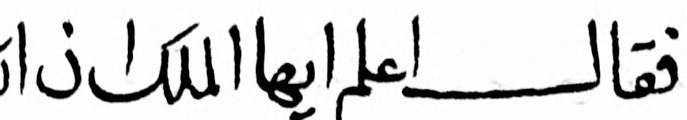
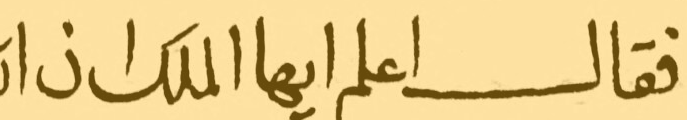
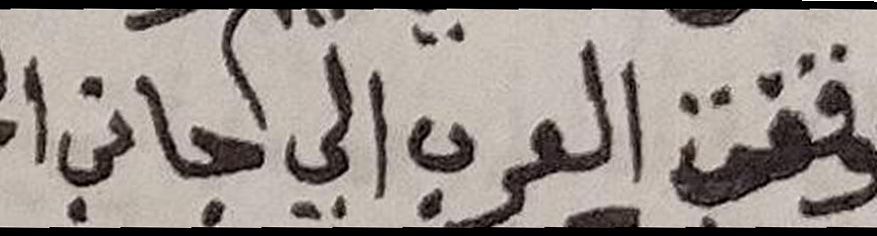
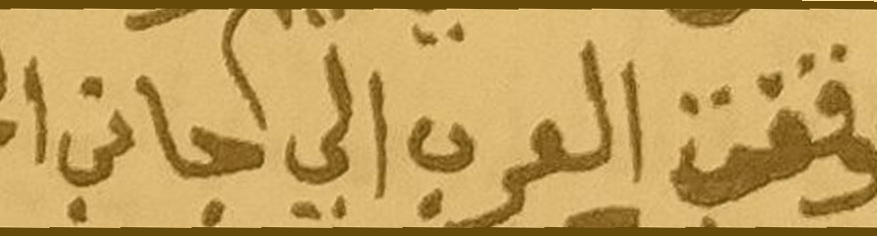

"R1 / Line ASource x: [23, 885)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 862 × 129 pxOriginal-resolution region crop — 862 × 129 px","R1 / Line BSource x: [1507, 2879)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 1372 × 295 pxOriginal-resolution region crop — 1372 × 295 px"

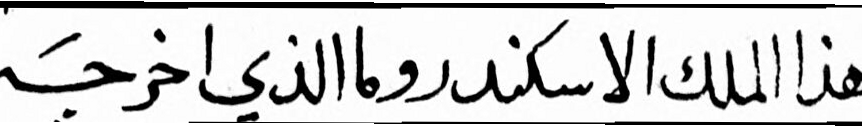
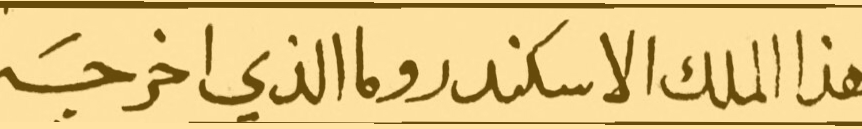
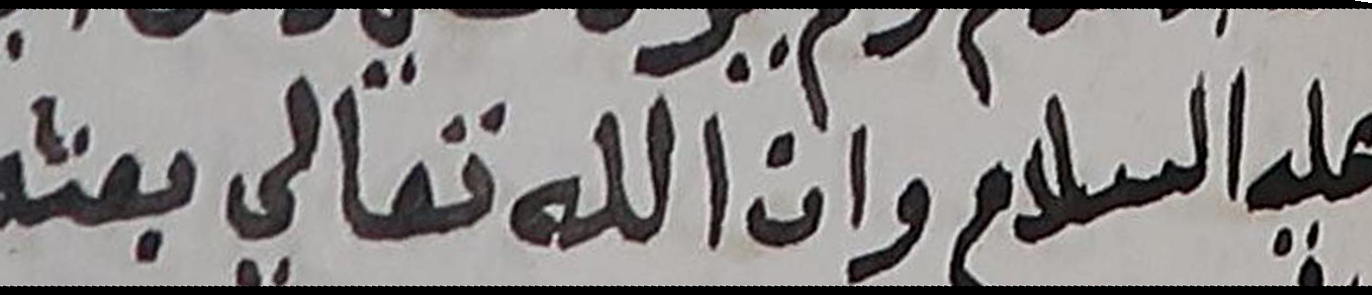
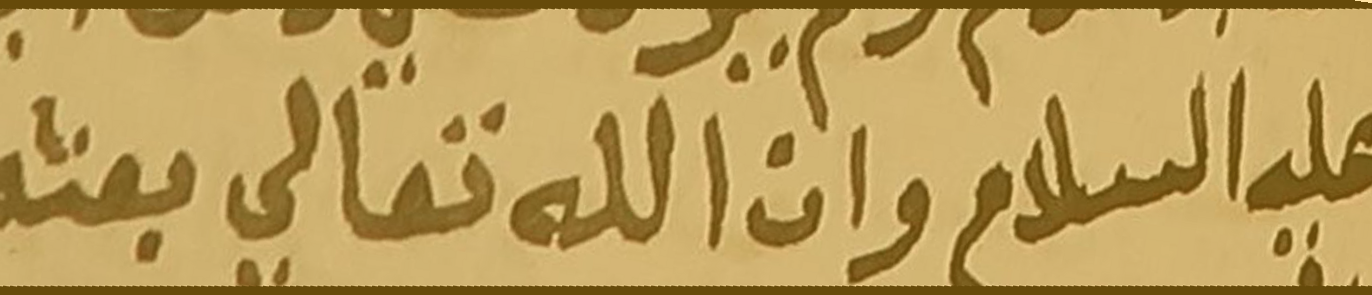

"R1 / Line ASource x: [325, 1420)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 1095 × 129 pxOriginal-resolution region crop — 1095 × 129 px","R1 / Line BSource x: [939, 2506)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 1567 × 218 pxOriginal-resolution region crop — 1567 × 218 px"

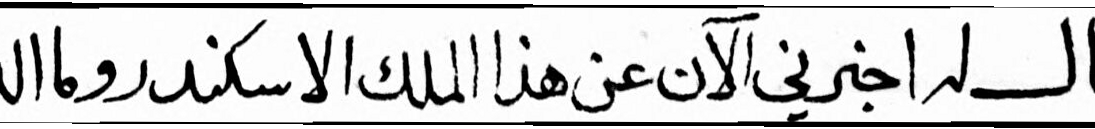
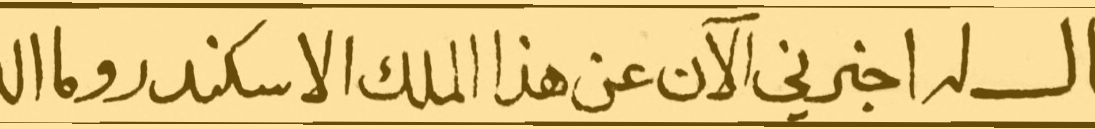
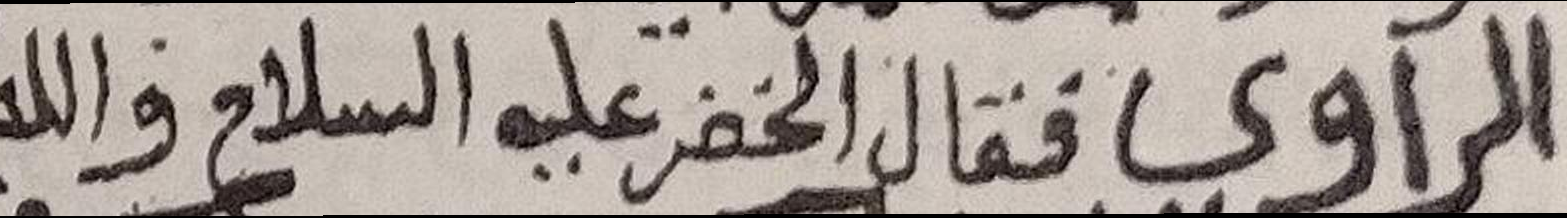
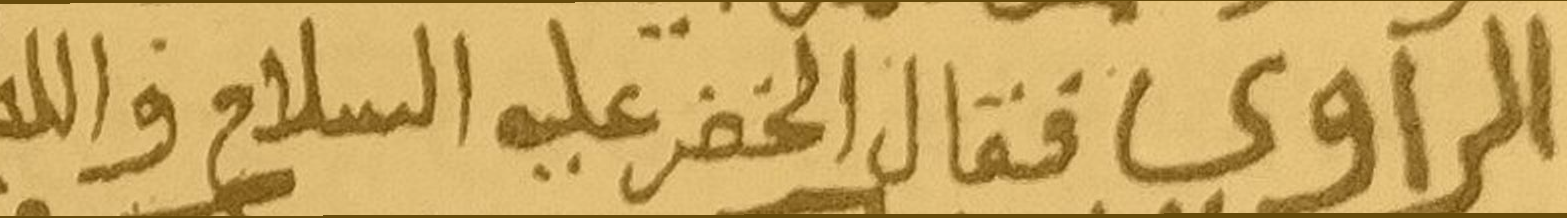

"R1 / Line ASource x: [697, 838)Transcript occurrence(s): Word absent from transcriptOriginal-resolution region crop — 141 × 129 pxOriginal-resolution region crop — 141 × 129 px","R1 / Line BSource x: [713, 1160)Transcript occurrence(s): Word absent from transcriptOriginal-resolution region crop — 447 × 290 pxOriginal-resolution region crop — 447 × 290 px"
"R2 / Line ASource x: [325, 559)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 234 × 129 pxOriginal-resolution region crop — 234 × 129 px","R2 / Line BSource x: [89, 714)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 625 × 290 pxOriginal-resolution region crop — 625 × 290 px"

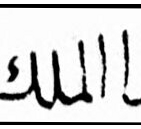
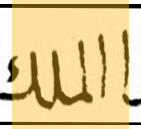
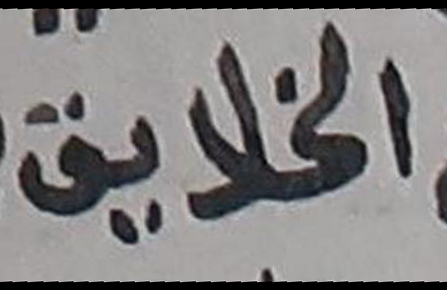
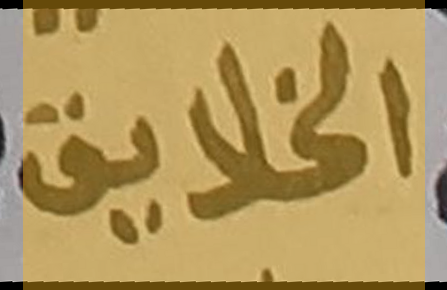
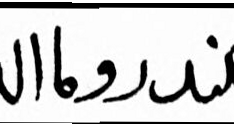
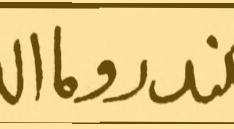
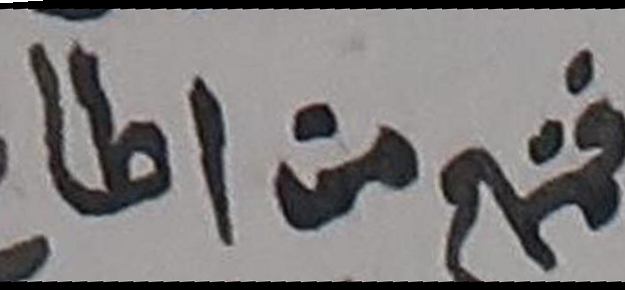
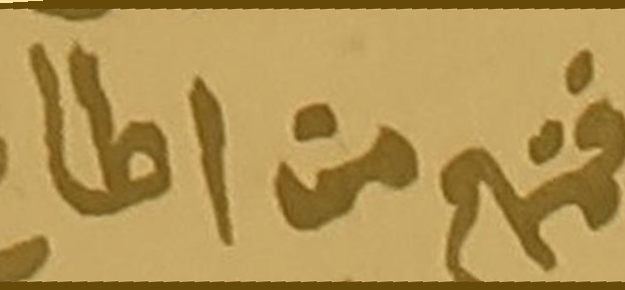

In [184]:
from evaluation_utils import REPRESENTATIONS, sample_random_pairs, print_candidate_diagnostics
negative_pairs = sample_random_pairs(session.pairs, N_NEGATIVE_SAMPLES, aligned=False, seed=RANDOM_SEED)
print("Presumed non-partner comparison samples:", len(negative_pairs))
negative_results = {}
for pair in negative_pairs:
    print("Same unaligned comparison pair in all representations:", pair["sample_id"])
    results = {}
    for rep in SHOWN_REPRESENTATIONS:
        result = session.evaluate_pair(pair, rep)
        results[rep] = result
        print(f"\n===== {rep.upper()} — {pair['sample_id']} =====")
        print_candidate_diagnostics(result, MAX_REJECTED_PATHS_TO_PLOT)
        fig = plot_qualitative_alignment(session, result, show_gt=SHOW_GT_MASKS,
                                  max_rejected_paths=MAX_REJECTED_PATHS_TO_PLOT, show_input_crop=True)
        display(fig)
        plt.close(fig)
    negative_results[pair["sample_id"]] = results
    display(pd.DataFrame({rep.upper(): {
        name: results[rep]["metrics"].get(name) for name in KEY_METRICS}
        for rep in SHOWN_REPRESENTATIONS}).rename_axis("metric"))


## 6. Candidate diagnostics and sample metrics
Route diagnostics print with each sample. This table summarizes the displayed sample slots.

Each displayed slot contributes one row per representation so all three can be compared.


In [185]:
if sample_slots:
    display(pd.DataFrame([
        dict(slot=slot, sample_id=sample["pair"]["sample_id"], representation=rep.upper(),
             threshold=result["settings"]["threshold"], label=sample["pair"]["label"],
             **{key: result["metrics"].get(key) for key in KEY_METRICS})
        for slot, sample in sorted(sample_slots.items())
        for rep, result in sample.get("results", {}).items()
    ]))
else:
    print("Run a sample cell first; no samples have been evaluated.")


,slot,sample_id,representation,threshold,label,pair_score,path_cosine_mean,path_cosine_median,path_cosine_min,maximum_similarity,off_path_cosine_mean,similarity_separation,path_length,region_count,matched_windows_a,matched_windows_b,total_windows_a,total_windows_b,mask_coverage_a,mask_coverage_b
0,1,ArabicData2:csv:331,FUSED,0.5,stored_aligned_pair,0.000000,NaN,NaN,NaN,0.893147,0.264975,NaN,0,0,0,0,63,63,0.000000,0.000000
1,2,ArabicData2:csv:482,FUSED,0.5,stored_aligned_pair,32.970332,0.607581,0.624399,0.157537,0.913248,0.291653,0.315928,42,1,27,29,63,63,0.469707,0.531923


### Mask accuracy — deferred until annotation

No ground-truth masks or accuracy tables are used during qualitative inspection.


In [186]:
# Retained quantitative section; inactive during qualitative review.
print("Mask accuracy deferred until ground-truth masks are annotated.")


Mask accuracy deferred until ground-truth masks are annotated.


<a id="ab-quantitative-600"></a>
## 7. Quantitative evaluation — deferred

Retain the original 300 aligned / 300 presumed non-partner count controls for
later work. No quantitative cohort, accuracy or mask metrics run now. After mask
annotation, the scoring workflow must be adapted to ArabicData2's CSV catalog.


In [187]:
# Quantitative evaluation will be added after mask annotation.
print("Qualitative mode: quantitative evaluation is deferred until masks are annotated.")


Qualitative mode: quantitative evaluation is deferred until masks are annotated.


## 8. Parameter validation — deferred

Matching parameters remain fixed for qualitative inspection. Revisit validation after annotation.


In [188]:
# Retained experiment section; parameters stay fixed during qualitative review.
print("Parameter sweeps deferred; use the sample views to inspect current predictions.")


Parameter sweeps deferred; use the sample views to inspect current predictions.


## Optional alignment-mode scoring — deferred

Retained section for later validation. Inspect the configured decoder visually now.


In [189]:
# Retained experiment section; parameters stay fixed during qualitative review.
print("Alignment-mode scoring deferred; use the sample views to inspect current predictions.")


Alignment-mode scoring deferred; use the sample views to inspect current predictions.


### Threshold and repeat-control experiment — deferred

No parameter search runs during qualitative review.


In [190]:
# Retained experiment section; parameters stay fixed during qualitative review.
print("Threshold/repeat scoring deferred; use the sample views to inspect current predictions.")


Threshold/repeat scoring deferred; use the sample views to inspect current predictions.


## Optional window-to-letter recognition

The following cells are opt-in and inspect only `RECOGNITION_SLOT` or `INSPECT_SLOT`. Full-alphabet embeddings and Top-k are constructed lazily when a recognition function is actually called. The main sample cells do no letter-recognition work.


In [191]:
def ensure_recognition_alphabet():
    if (session.settings.get('candidate_similarity_mode') or session.settings.get('similarity_mode')) == 'bidirectional_window':
        raise ValueError("Letter recognition is disabled in image-only bidirectional_window mode")
    global FULL_ALPHABET, alphabet_vectors, alphabet_lookup
    from losses import effective_alphabet
    alphabet_key = (session.checkpoint_sha256, str(session.device))
    if globals().get('_recognition_alphabet_key') == alphabet_key:
        return
    FULL_ALPHABET = effective_alphabet(session.config, session.text_encoder)
    assert TOP_K >= 3 and TOP_K <= len(FULL_ALPHABET)
    with torch.no_grad():
        alphabet_vectors = session.text_encoder.encode(''.join(FULL_ALPHABET)).float()
    assert alphabet_vectors.shape == (len(FULL_ALPHABET), session.config.embedding_dim)
    assert torch.isfinite(alphabet_vectors).all()
    alphabet_lookup = {letter: index for index, letter in enumerate(FULL_ALPHABET)}
    globals()['_recognition_alphabet_key'] = alphabet_key
    print(f'Checkpoint alphabet: {len(FULL_ALPHABET)} identities; space={" " in FULL_ALPHABET}.')


### Transcript-specific cosine and DTW

This is separate from image-image matching threshold tuning. The hard DTW diagnostic works on CPU costs so MPS does not attempt unsupported float64 conversion. It uses the checkpoint's own cost mode/penalties and does not change training.

The checkpoint controls the alphabet and transcript tokenization. Optional spaces may be skipped with zero windows or matched to one or more windows. Recognition metrics report skipped/matched spaces; space is a separate identity from CTC blank.

The diagnostic backtrace follows the optional-space training recurrence from commit `de0bac3`, using the saved skip penalty and the same full-transcript horizontal suppression. See [the evaluation notes](../docs/optional_space_evaluation.md).


In [192]:
def cosine_checked(visual, letters):
    assert visual.ndim == letters.ndim == 2 and visual.shape[1] == letters.shape[1]
    assert torch.isfinite(visual).all() and torch.isfinite(letters).all()
    scores = cosine_similarity_matrix(visual, letters)
    assert torch.isfinite(scores).all()
    assert bool(((scores >= -1.00001) & (scores <= 1.00001)).all())
    return scores


def spatial_character_gt(side, letters, source_interval_x):
    """Use only explicit source-pixel character boxes with transcript positions."""
    boxes = side.get('character_boxes')
    # Existing character boxes count Arabic letters; optional spaces add token positions.
    letter_positions = [j for j, token in enumerate(letters) if token != ' ']
    if boxes is None:
        return None
    start, end = source_interval_x
    overlaps = []
    for box in boxes:
        position = int(box['text_position'])
        if side.get('character_box_positions', 'letters') == 'letters':
            position = letter_positions[position]
        character = box['character']
        assert 0 <= position < len(letters) and letters[position] == character
        left, right = float(box['x_start']), float(box['x_end'])
        assert left < right
        shared = max(0., min(end, right) - max(start, left))
        if shared > 0:
            overlaps.append(dict(position=position, character=character,
                                 overlap_ratio=shared / (end - start),
                                 character_overlap_ratio=shared / (right - left)))
    overlaps.sort(key=lambda item: (-item['overlap_ratio'], item['position']))
    return overlaps


def recognize_line(session, side, line, top_k=5):
    # get_line_features caches the exact output['fused'][0][token_valid] of model.forward.
    visual = line['features']['fused'].to(session.device).float()
    physical = np.asarray(line['physical'], dtype=int)
    model_indices = np.asarray(line['logical'], dtype=int)
    expected = (session.config.image_width - session.config.window_width) // session.config.window_stride + 1
    assert len(visual) == len(physical) == len(model_indices) > 0
    assert len(np.unique(physical)) == len(physical)
    assert np.all((physical >= 0) & (physical < expected))
    assert np.all((model_indices >= 0) & (model_indices < expected))
    assert np.all(np.diff(model_indices) > 0)  # invalid/padded tokens were removed
    assert np.array_equal(physical, expected - 1 - model_indices if session.config.rtl else model_indices)
    assert visual.shape[1] == alphabet_vectors.shape[1]
    assert torch.isfinite(visual).all()
    assert torch.allclose(visual.norm(dim=-1), torch.ones(len(visual), device=visual.device), atol=1e-4)

    from text_embedding import read_side_text
    from losses import alignment_tokens, effective_alphabet
    letters = alignment_tokens(read_side_text(side), session.config)
    if not letters:
        raise ValueError(f'Empty cleaned transcript: {side["text"]}')
    assert set(letters).issubset(alphabet_lookup)
    with torch.no_grad():
        # All characters: independent of transcript and of the DTW result.
        full = cosine_checked(visual, alphabet_vectors.to(visual.device))
        top_scores, top_ids = full.topk(top_k, dim=1)
        transcript_vectors = session.text_encoder.encode(''.join(letters)).float()
        assert transcript_vectors.shape == (len(letters), visual.shape[1])
        for position, letter in enumerate(letters):
            assert torch.allclose(transcript_vectors[position], alphabet_vectors[alphabet_lookup[letter]], atol=1e-6)
        transcript = cosine_checked(visual, transcript_vectors)
        assert transcript.shape == (len(visual), len(letters))  # repeated identities retain positions
        inventory = effective_alphabet(session.config, session.text_encoder, letters)
        costs = letter_cost_matrix(
            visual, transcript_vectors,
            alphabet=session.text_encoder.encode(''.join(inventory)),
            letter_ids=[inventory.index(letter) for letter in letters],
            temperature=session.config.competition_temperature,
            mode=session.config.dtw_cost_mode)
        # hard_dtw_path uses float64 internally; MPS cannot do float64.
        # Copy the tiny DTW cost matrix to CPU BEFORE hard_dtw_path.
        alignment = hard_dtw_path(costs.detach().float().cpu(), session.config.vertical_penalty,
                             session.config.horizontal_penalty, session.config.position_prior,
                             session.config.disable_horizontal_when_feasible,
                             space_columns=([c == ' ' for c in letters]
                                            if session.config.space_mode == 'optional' else None),
                             space_skip_penalty=(session.config.space_skip_penalty_ratio * float(np.log(len(inventory)))
                                                 if session.config.space_mode == 'optional' else 0.))
        path = alignment.path
    assert full.shape == (len(visual), len(FULL_ALPHABET))
    assert len(path) and all(0 <= i < len(visual) and 0 <= j < len(letters) for i, j in path)
    positions_by_model = [[] for _ in visual]
    for i, j in path:
        if j not in positions_by_model[i]:
            positions_by_model[i].append(j)
    assert all(positions_by_model)
    for letter in set(letters):
        repeated = [j for j, value in enumerate(letters) if value == letter]
        for j in repeated[1:]:
            assert torch.allclose(transcript[:, repeated[0]], transcript[:, j], atol=1e-6)

    records = []
    for model_index, physical_index in enumerate(physical):
        x_start = int(physical_index * session.config.window_stride)
        x_end = x_start + session.config.window_width
        source_start, source_end = source_interval(int(physical_index), line['geometry'],
                                                   session.config.window_width, session.config.window_stride)
        overlapping = spatial_character_gt(side, letters, (source_start, source_end))
        primary_gt = overlapping[0] if overlapping else None
        aligned_positions = positions_by_model[model_index]
        dtw_position = min(aligned_positions, key=lambda j: (-float(transcript[model_index, j]), j))
        best_letters = [FULL_ALPHABET[int(index)] for index in top_ids[model_index]]
        record = dict(physical_window_index=int(physical_index), model_sequence_index=int(model_indices[model_index]),
                      token_valid=True, x_start=x_start, x_end=x_end,
                      source_x_start=float(source_start), source_x_end=float(source_end),
                      gt_primary_letter=None if primary_gt is None else primary_gt['character'],
                      gt_primary_text_position=None if primary_gt is None else primary_gt['position'],
                      gt_primary_overlap_ratio=None if primary_gt is None else primary_gt['overlap_ratio'],
                      gt_overlapping_letters=None if overlapping is None else [x['character'] for x in overlapping],
                      gt_overlapping_positions=None if overlapping is None else [x['position'] for x in overlapping],
                      gt_overlap_ratios=None if overlapping is None else [x['overlap_ratio'] for x in overlapping],
                      top1_score=float(top_scores[model_index, 0]), top2_score=float(top_scores[model_index, 1]),
                      cosine_margin=float(top_scores[model_index, 0] - top_scores[model_index, 1]),
                      cos_top1_is_space=best_letters[0] == ' ',
                      dtw_is_space=letters[dtw_position] == ' ',
                      dtw_character=letters[dtw_position], dtw_text_position=int(dtw_position),
                      dtw_all_text_positions=aligned_positions,
                      dtw_all_characters=[letters[j] for j in aligned_positions],
                      dtw_cosine=float(transcript[model_index, dtw_position]))
        for rank, (letter, score) in enumerate(zip(best_letters, top_scores[model_index]), 1):
            record[f'cos_top{rank}_letter'] = letter
            record[f'cos_top{rank}_score'] = float(score)
        record['cos_correct'] = None if primary_gt is None else best_letters[0] == primary_gt['character']
        record['dtw_correct'] = None if primary_gt is None else letters[dtw_position] == primary_gt['character']
        record['dtw_position_correct'] = None if primary_gt is None else dtw_position == primary_gt['position']
        record['cos_dtw_agree'] = best_letters[0] == letters[dtw_position]
        records.append(record)
    frame = pd.DataFrame(records).sort_values('physical_window_index').reset_index(drop=True)
    assert frame['physical_window_index'].is_unique and frame['token_valid'].all()
    return dict(frame=frame, alphabet_cosine=full.cpu().numpy(), transcript_cosine=transcript.cpu().numpy(),
                letters=letters, path=path, physical=physical, top_k=top_k,
                skipped_space_positions=alignment.skipped_columns,
                matched_space_positions=sorted({j for _, j in path if letters[j] == ' '}),
                gt_available=side.get('character_boxes') is not None)


def recognize_slot(slot):
    if slot not in sample_slots:
        raise ValueError(f"Sample slot {slot} is empty.")
    ensure_recognition_alphabet()
    sample = sample_slots[slot]
    key = (sample["pair"]["sample_id"], sample["base"]["representation"], TOP_K)
    if key not in recognitions:
        pair, result = sample["pair"], sample["base"]
        recognitions[key] = {
            name: recognize_line(session, pair["sides"][side],
                                 result["lines"][side], TOP_K)
            for side, name in enumerate(("A", "B"))
        }
        print("Window-letter recognition computed once for slot", slot)
    return recognitions[key]


## 7. Full-alphabet cosine recognition — Line A

Opt-in: set ENABLE_RECOGNITION_TABLES=True and select RECOGNITION_SLOT, or run the function directly. Other sample slots are not evaluated.


In [193]:
def show_line_recognition(slot, name):
    diagnostic = recognize_slot(slot)[name]
    frame = diagnostic["frame"]
    print(f"Sample {slot} / Line {name}: {len(frame)} windows, "
          f"alphabet={len(FULL_ALPHABET)}, transcript={len(diagnostic['letters'])}")
    if not diagnostic["gt_available"]:
        print("Character-level spatial GT unavailable")
    print('Skipped space positions:', diagnostic.get('skipped_space_positions', []),
          '| matched space positions:', diagnostic.get('matched_space_positions', []))
    display(frame)
    return frame

if ENABLE_RECOGNITION_TABLES and not image_only_window_mode() and RECOGNITION_SLOT in sample_slots:
    show_line_recognition(RECOGNITION_SLOT, "A")


## 8. Full-alphabet cosine recognition — Line B

Opt-in; this cell displays only Line B for RECOGNITION_SLOT.


In [194]:
if ENABLE_RECOGNITION_TABLES and not image_only_window_mode() and RECOGNITION_SLOT in sample_slots:
    show_line_recognition(RECOGNITION_SLOT, "B")


## 9. Cosine versus DTW comparison (selected sample only)


In [195]:
comparison_columns = [
    "physical_window_index", "model_sequence_index", "x_start", "x_end",
    "gt_primary_letter", "gt_primary_text_position", "gt_overlapping_letters",
    "gt_overlapping_positions", "gt_overlap_ratios", "cos_top1_letter",
    "top1_score", "cos_top2_letter", "top2_score", "cosine_margin",
    "cos_top1_is_space", "dtw_is_space", "dtw_character", "dtw_text_position", "dtw_all_text_positions",
    "dtw_cosine", "cos_correct", "dtw_correct", "cos_dtw_agree"
]

def compare_recognition(slot):
    for name, diagnostic in recognize_slot(slot).items():
        frame = diagnostic["frame"]
        print(f"Sample {slot} / Line {name}: cosine–DTW agreement "
              f"{frame['cos_dtw_agree'].mean():.1%} "
              f"({frame['cos_dtw_agree'].sum()}/{len(frame)})")
        display(frame[comparison_columns])

if ENABLE_RECOGNITION_TABLES and RECOGNITION_SLOT in sample_slots:
    compare_recognition(RECOGNITION_SLOT)


## 10. Supervised recognition metrics — disabled

Character-level scoring is outside the current qualitative review.


In [196]:
def recognition_metrics(diagnostic):
    frame = diagnostic['frame']
    margins = frame['cosine_margin'].to_numpy(dtype=float)
    summary = dict(evaluated_windows=len(frame), alphabet_characters=len(FULL_ALPHABET),
                   transcript_positions=len(diagnostic['letters']),
                   transcript_spaces=diagnostic['letters'].count(' '),
                   skipped_spaces=len(diagnostic.get('skipped_space_positions', [])),
                   matched_spaces=len(diagnostic.get('matched_space_positions', [])),
                   predicted_space_windows=int((frame['cos_top1_letter'] == ' ').sum()),
                   mean_top1_cosine=float(frame['top1_score'].mean()),
                   mean_top2_cosine=float(frame['top2_score'].mean()),
                   mean_cosine_margin=float(margins.mean()),
                   median_cosine_margin=float(np.median(margins)),
                   min_cosine_margin=float(margins.min()),
                   max_cosine_margin=float(margins.max()),
                   cosine_dtw_agreement=float(frame['cos_dtw_agree'].mean()))
    valid = frame[frame['gt_primary_letter'].notna()]
    summary['gt_evaluated_windows'] = len(valid)
    summary['ambiguous_multi_letter_windows'] = int(sum(
        len(set(positions or [])) > 1 for positions in valid['gt_overlapping_positions']))
    keys = ('cosine_top1_character_accuracy', 'cosine_top3_character_accuracy',
            'cosine_top1_overlap_accuracy', 'cosine_top3_overlap_accuracy',
            'dtw_character_accuracy', 'dtw_position_aware_accuracy', 'dtw_overlap_accuracy',
            'mean_margin_correct', 'mean_margin_incorrect')
    summary.update({key: None for key in keys})
    category_names = ('Cos correct + DTW correct', 'Cos correct + DTW wrong',
                      'Cos wrong + DTW correct', 'Cos wrong + DTW wrong')
    categories = {key: dict(count=0, percent=None) for key in category_names}
    if len(valid):
        top3 = lambda row: [row[f'cos_top{i}_letter'] for i in (1, 2, 3)]
        fraction = lambda predicate: sum(bool(predicate(row)) for _, row in valid.iterrows()) / len(valid)
        summary.update(
            cosine_top1_character_accuracy=fraction(lambda row: row['cos_correct']),
            cosine_top3_character_accuracy=fraction(lambda row: row['gt_primary_letter'] in top3(row)),
            cosine_top1_overlap_accuracy=fraction(lambda row: row['cos_top1_letter'] in row['gt_overlapping_letters']),
            cosine_top3_overlap_accuracy=fraction(lambda row: bool(set(top3(row)) & set(row['gt_overlapping_letters']))),
            dtw_character_accuracy=fraction(lambda row: row['dtw_correct']),
            dtw_position_aware_accuracy=fraction(lambda row: row['dtw_position_correct']),
            dtw_overlap_accuracy=fraction(lambda row: row['dtw_text_position'] in row['gt_overlapping_positions']),
        )
        correct = valid[valid['cos_correct'] == True]['cosine_margin']
        wrong = valid[valid['cos_correct'] == False]['cosine_margin']
        summary['mean_margin_correct'] = float(correct.mean()) if len(correct) else None
        summary['mean_margin_incorrect'] = float(wrong.mean()) if len(wrong) else None
        for _, row in valid.iterrows():
            label = f'Cos {"correct" if row["cos_correct"] else "wrong"} + DTW {"correct" if row["dtw_correct"] else "wrong"}'
            categories[label]['count'] += 1
        for value in categories.values():
            value['percent'] = value['count'] / len(valid)
    return summary, categories


def show_recognition_metrics(slot):
    metric_rows, category_rows = [], []
    for name, diagnostic in recognize_slot(slot).items():
        metrics, categories = recognition_metrics(diagnostic)
        metric_rows.append(dict(slot=slot, sample_id=sample_slots[slot]["pair"]["sample_id"],
                                line=name, **metrics))
        for category, value in categories.items():
            category_rows.append(dict(slot=slot, line=name, category=category, **value))
    display(pd.DataFrame(metric_rows))
    display(pd.DataFrame(category_rows))
    if all(row["gt_evaluated_windows"] == 0 for row in metric_rows):
        print("Character-level spatial GT unavailable; character accuracy cannot be scored.")
    return metric_rows

if ENABLE_RECOGNITION_METRICS and not image_only_window_mode() and RECOGNITION_SLOT in sample_slots:
    show_recognition_metrics(RECOGNITION_SLOT)


## 11. Optional alphabet heatmaps

**Window × Full Alphabet** shows representation cosine. **Window × Transcript Positions** retains repeated text positions and shows the cosine matrix used alongside DTW. The DTW path is overlaid only on the transcript plot. Both plots display rows in physical image order; transcript columns follow reading order. They are separate figures to keep labels readable.


In [197]:
def plot_recognition_heatmaps(diagnostic, sample_id, line_name):
    frame = diagnostic['frame']
    physical_order = np.argsort(diagnostic['physical'])
    labels = frame['physical_window_index'].astype(str).tolist()
    if SHOW_ALPHABET_HEATMAP:
        full = diagnostic['alphabet_cosine'][physical_order]
        fig, ax = plt.subplots(figsize=(max(17, .32 * len(FULL_ALPHABET)),
                                        max(6, .24 * len(frame))))
        heat = ax.imshow(full, aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
        ax.set_xticks(np.arange(len(FULL_ALPHABET)), ['SPACE' if c == ' ' else c for c in FULL_ALPHABET], rotation=90, fontsize=7)
        ax.set_yticks(np.arange(len(frame)), labels, fontsize=7)
        ax.set(xlabel='Full supported alphabet (character identity)', ylabel='Physical window index (left → right)',
               title=f'{sample_id} / {line_name}: Full-Alphabet Window ↔ Letter Cosine Similarity')
        if MARK_TOP1:
            ax.scatter([alphabet_lookup[x] for x in frame['cos_top1_letter']],
                       np.arange(len(frame)), marker='x', color='black', s=20)
        fig.colorbar(heat, ax=ax, label='cosine')
        fig.tight_layout()
        display(fig)
        plt.close(fig)
    matrix = diagnostic['transcript_cosine'][physical_order]
    fig, ax = plt.subplots(figsize=(max(12, .35 * len(diagnostic['letters'])),
                                    max(5, .22 * len(frame))))
    heat = ax.imshow(matrix, aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(np.arange(len(diagnostic['letters'])),
                  [f'{i}:' + ('SPACE' if c == ' ' else c) for i, c in enumerate(diagnostic['letters'])], rotation=90, fontsize=8)
    ax.set_yticks(np.arange(len(frame)), labels, fontsize=7)
    physical_row_of_compact_model = np.empty(len(physical_order), dtype=int)
    physical_row_of_compact_model[physical_order] = np.arange(len(physical_order))
    ax.plot([j for i, j in diagnostic['path']],
            [physical_row_of_compact_model[i] for i, j in diagnostic['path']], '.-', color='black', ms=3, lw=.8)
    ax.set(xlabel='Transcript text position (reading order)', ylabel='Physical window index (left → right)',
           title=f'{sample_id} / {line_name}: Window × Transcript-Position Cosine and DTW Path')
    fig.colorbar(heat, ax=ax, label='cosine')
    fig.tight_layout()
    display(fig)
    plt.close(fig)


def show_recognition_heatmaps(slot):
    diagnostics = recognize_slot(slot)
    sample_id = sample_slots[slot]["pair"]["sample_id"]
    for name in ("A", "B"):
        plot_recognition_heatmaps(diagnostics[name], sample_id, name)

if image_only_window_mode():
    print("Letter recognition skipped: image-only bidirectional_window mode.")
elif not ENABLE_RECOGNITION_HEATMAPS:
    print('Heatmaps skipped: ENABLE_RECOGNITION_HEATMAPS is False (set True in the setup cell, rerun it, then rerun all cells).')
elif RECOGNITION_SLOT not in sample_slots:
    print(f'Heatmaps skipped: slot {RECOGNITION_SLOT} not in sample_slots {sorted(sample_slots)}. Run the sample cells after the setup cell.')
else:
    show_recognition_heatmaps(RECOGNITION_SLOT)


Heatmaps skipped: ENABLE_RECOGNITION_HEATMAPS is False (set True in the setup cell, rerun it, then rerun all cells).


## 12. Optional single-window inspector (selected sample only)

This is the only cell that shows an individual cropped window. Set SHOW_WINDOW_INSPECTOR=True and INSPECT_SLOT to inspect a cached sample; it will not rerun other samples.


In [198]:
if not image_only_window_mode() and SHOW_WINDOW_INSPECTOR and INSPECT_SLOT in sample_slots:
    assert INSPECT_LINE in ('A', 'B')
    pair = sample_slots[INSPECT_SLOT]['pair']
    result = sample_slots[INSPECT_SLOT]['base']
    side_index = ('A', 'B').index(INSPECT_LINE)
    side = pair['sides'][side_index]
    diagnostic = recognize_slot(INSPECT_SLOT)[INSPECT_LINE]
    selected = diagnostic['frame'].loc[
        diagnostic['frame']['physical_window_index'] == WINDOW_INDEX]
    if selected.empty:
        print(f'Physical window {WINDOW_INDEX} is outside the valid grid for this line.')
    else:
        row = selected.iloc[0]
        geometry = result['lines'][side_index]['geometry']
        with Image.open(side['image']) as source:
            assert source.size == tuple(geometry['source_size'])
            left=max(0,int(np.floor(row.source_x_start)))
            right=min(source.width,int(np.ceil(row.source_x_end)))
            native_window=source.crop((left,0,right,source.height))
        display(HTML(native_image_html(native_window,
            f'{pair["sample_id"]} / {INSPECT_LINE} / physical window {WINDOW_INDEX} — source pixels')))
        print('Physical window:', row.physical_window_index,
              '| model sequence index:', row.model_sequence_index,
              '| source x-range:', (row.source_x_start, row.source_x_end))
        print('GT primary:', row.gt_primary_letter, '| GT overlaps:', row.gt_overlapping_letters)
        for rank in range(1, TOP_K + 1):
            print(f'{rank}. {row[f"cos_top{rank}_letter"]}  {row[f"cos_top{rank}_score"]:.4f}')
        print(f'Top1/Top2 margin: {row.cosine_margin:.4f}')
        print('DTW:', row.dtw_character, '| primary text position:', row.dtw_text_position,
              '| all path positions:', row.dtw_all_text_positions,
              '| transcript cosine:', row.dtw_cosine)


## Save only one existing sample — opt-in

Set SAVE_RESULTS=True and SAVE_SLOT to save **one** cached sample under Results/Evaluation. Nothing is saved automatically when tuning thresholds or rerunning other sample cells.


In [199]:
OUTPUT = None
if SAVE_RESULTS:
    if SAVE_SLOT not in sample_slots:
        print(f"Sample slot {SAVE_SLOT} is empty; nothing saved.")
    else:
        sample = sample_slots[SAVE_SLOT]
        result = sample.get("result") or evaluate_cached_sample(SAVE_SLOT)
        OUTPUT = (project_path(RESULTS_ROOT) / session.checkpoint.parent.name /
                  (f"{session.split}_slot_{SAVE_SLOT}_" + uuid.uuid4().hex[:12]))
        save_pair_artifacts(session, result, OUTPUT)
        fig = plot_qualitative_alignment(session, result, show_window_indices=True)
        fig.savefig(OUTPUT / "pair_figure.png", dpi=110)
        plt.close(fig)
        (OUTPUT / "run_settings.json").write_text(json.dumps(dict(
            checkpoint=str(session.checkpoint), checkpoint_sha256=session.checkpoint_sha256,
            split=session.split, seed=RANDOM_SEED, representation=REPRESENTATION,
            matching_settings=result["settings"], selected_pair_id=sample["pair"]["sample_id"]), indent=2))
else:
    print("Saving disabled; enable SAVE_RESULTS and select SAVE_SLOT to save one sample.")


Saving disabled; enable SAVE_RESULTS and select SAVE_SLOT to save one sample.


## Interpretation

Compare predicted regions on source images, overlays and heatmaps. Route scores,
cosine values, coverage and feature statistics describe model behavior, not
accuracy or calibrated confidence. No ground-truth mask is loaded or generated.
Recorded partners can overlap partially; non-partners are presumed examples.
Quantitative correctness and localization will be checked after mask annotation.


## Same-checkpoint population comparison — deferred

Use the sample representation cells for qualitative comparison now.


In [200]:
# Retained population-comparison section.
print("Population comparison deferred; inspect LOCAL/FUSED/CONTEXT sample views.")


Population comparison deferred; inspect LOCAL/FUSED/CONTEXT sample views.


## Transcript ranking — deferred

Supervised ranking is disabled during qualitative inspection.


In [201]:
# Retained supervised-ranking section.
print("Supervised ranking disabled during qualitative review.")


Supervised ranking disabled during qualitative review.


# Phase 1 — Qualitative representation and alignment diagnostics

Run setup, session and matching settings first, then the cells below in order.
Use the same fixed CSV partner or presumed non-partner across LOCAL, FUSED and
CONTEXT. Inspect source lines, predicted masks/overlays, heatmaps and routes.
Feature statistics and indexing checks describe the prediction process. No
ground-truth masks or accuracy scores are used. Available samples may be fewer
than the configured sample limits; missing sample slots are skipped.


In [202]:
# PHASE 1 CONFIGURATION — sampling/report limits only, no matcher tuning.
RUN_PHASE1 = True
PHASE1_SEED = 42
PHASE1_N_POSITIVE = 5
PHASE1_N_NEGATIVE = 5
PHASE1_FIXED_POSITIVE_IDS = []
PHASE1_FIXED_NEGATIVE_IDS = []
PHASE1_MAX_POPULATION_PAIRS = 300  # 0 = complete saved-test catalog; seeded subset otherwise
PHASE1_COLLAPSE_MAX_LINES = 100
PHASE1_COLLAPSE_MAX_WINDOWS = 1024
PHASE1_SHOW_GT = False

from copy import copy, deepcopy
from PIL import Image
from evaluation_utils import (
    REPRESENTATIONS, sample_random_pairs,
    representation_diagnostics, indexing_sanity, feature_diagnostics,
    evaluate_population, aggregate_summary, plot_pair_alignment, plot_representation_comparison,
)

def phase1_select(records, fixed_ids, n, aligned):
    catalog = {p['sample_id']: p for p in records if p['target'] == int(aligned)}
    if fixed_ids:
        if len(set(fixed_ids)) != len(fixed_ids):
            raise ValueError('Phase 1 fixed IDs must be unique')
        missing = [sid for sid in fixed_ids if sid not in catalog]
        if missing:
            raise ValueError(f'Fixed Phase 1 IDs missing from saved test/label catalog: {missing}')
        return [catalog[sid] for sid in fixed_ids]
    return sample_random_pairs(list(catalog.values()), n, aligned=aligned, seed=PHASE1_SEED)

if RUN_PHASE1:
    # Reuse the model and feature cache when already on test. Never fall back to train/val.
    if session.split == 'test':
        phase1_session = copy(session)
    else:
        phase1_session = QualitativeEvaluationSession(
            session.checkpoint, session.dataset_path, split='test', device=str(session.device),
            seed=PHASE1_SEED, construct_negatives=False, pair_source=session.pair_source,
            annotation_manifest=project_path(ANNOTATION_MANIFEST), crop_override=session.config.crop)
    phase1_session.seed = PHASE1_SEED
    phase1_session.settings = deepcopy(session.settings)
    phase1_settings = resolved_match_settings(phase1_session.settings)
    phase1_settings_json = json.dumps(phase1_settings, sort_keys=True)
    phase1_session.metric_cache = {}  # Diagnostic population cache, shared feature cache is retained.
    # Use the existing CSV partner and CSV non-partner comparison catalog.
    # CSV partners and presumed non-partners select qualitative examples only.
    phase1_catalog = list(phase1_session.pairs)
    phase1_catalog = sorted({p['sample_id']: p for p in phase1_catalog}.values(), key=lambda p: p['sample_id'])
    phase1_positive = phase1_select(phase1_catalog, PHASE1_FIXED_POSITIVE_IDS, PHASE1_N_POSITIVE, True)
    phase1_negative = phase1_select(phase1_catalog, PHASE1_FIXED_NEGATIVE_IDS, PHASE1_N_NEGATIVE, False)
    if PHASE1_MAX_POPULATION_PAIRS < 0:
        raise ValueError('PHASE1_MAX_POPULATION_PAIRS must be nonnegative')
    phase1_population_pairs = (random.Random(PHASE1_SEED).sample(
        phase1_catalog, min(PHASE1_MAX_POPULATION_PAIRS, len(phase1_catalog)))
        if PHASE1_MAX_POPULATION_PAIRS else list(phase1_catalog))
    phase1_session.pairs = phase1_population_pairs
    phase1_manifest = dict(checkpoint=str(phase1_session.checkpoint),
        checkpoint_sha256=phase1_session.checkpoint_sha256,
        available_subset_sha256=phase1_session.available_subset_sha256, split='test',
        seed=PHASE1_SEED, matcher_version=MATCH_VERSION, settings=phase1_settings,
        preprocessing=dict(crop=phase1_session.config.crop),
        mode="qualitative_without_ground_truth",
        positive_ids=[p['sample_id'] for p in phase1_positive],
        negative_ids=[p['sample_id'] for p in phase1_negative],
        population_ids=[p['sample_id'] for p in phase1_population_pairs])
    print('Fixed positive IDs:', phase1_manifest['positive_ids'])
    print('Fixed negative IDs:', phase1_manifest['negative_ids'])
    print('Checkpoint SHA256:', phase1_manifest['checkpoint_sha256'])
    print('Frozen matcher settings:', phase1_settings_json)
    print('Population:', 'complete' if len(phase1_population_pairs) == len(phase1_catalog) else 'seeded subset',
          len(phase1_population_pairs), 'of', len(phase1_catalog),
          'labels:', dict(Counter(p['target'] for p in phase1_population_pairs)))
    print('Set PHASE1_MAX_POPULATION_PAIRS=0 for the complete test catalog. IDs are in phase1_manifest.')
    print('Fusion:', phase1_session.config.fusion_mode,
          '| gate enabled:', bool(phase1_session.config.use_gated_fusion))
    if not phase1_negative:
        print('No presumed non-partners available in the selected catalog.')
    phase1_results, phase1_fixed_rows, phase1_sanity_rows = {}, [], []

Requested 5 unique positive samples, but only 2 eligible unique samples are available.
Fixed positive IDs: ['ArabicData2:csv:331', 'ArabicData2:csv:482']
Fixed negative IDs: ['ArabicData2:negative:BookA:429:BookB:485', 'ArabicData2:negative:BookA:415:BookB:485', 'ArabicData2:negative:BookA:415:BookB:482', 'ArabicData2:negative:BookA:415:BookB:80', 'ArabicData2:negative:BookA:424:BookB:80']
Checkpoint SHA256: dcda215d1167ba957a578bd494c7a889c8e86f485dc0b2a9f787db9aa95e6bf8
Frozen matcher settings: {"acceptance_offset": 0.1, "alignment_mode": "word_dtw", "allow_reordered_regions": true, "allow_short_regions": true, "anchor_top_k": 4, "candidate_similarity_mode": "letter_evidence", "contrast_margin": 0.05, "decoder": "word_dtw", "dominance_min_quality_ratio": 0.75, "enable_path_extension": false, "enable_region_merging": false, "extension_max_internal_gap": 2, "extension_max_weak_run": 1, "extension_min_reward": 0.0, "gap_extend": 0.5826132317598225, "gap_open": 0.5940936607241908, "max_c

## A–B. Fixed examples: separate LOCAL, FUSED, and CONTEXT cells

Each fixed sample retains three representation cells using the same pair.
Views show predicted masks, source overlays, raw cosine and predicted routes.
All cosine heatmaps use **[-1, 1]** and matching settings stay fixed. CSV labels
select examples only; no ground-truth mask or correctness score is used.


In [203]:
def phase1_show_pair(pair, representation=None):
    if representation is not None and representation not in REPRESENTATIONS:
        raise ValueError(f'Unknown representation: {representation}')
    # Preserve original-pair-first ordering in the LOCAL cell.
    if (representation is None or representation == 'local') and 'local' in SHOWN_REPRESENTATIONS:
        print('\nOriginal pair:', pair['sample_id'], '| stored label:', pair['label'])
        display_native_sources(pair)
    # Refresh this pair's diagnostic rows instead of duplicating them on reruns.
    phase1_fixed_rows[:] = [r for r in phase1_fixed_rows if r['sample_id'] != pair['sample_id']]
    phase1_sanity_rows[:] = [r for r in phase1_sanity_rows if r['sample_id'] != pair['sample_id']]
    pair_results, pair_rows = {}, {}
    for rep in REPRESENTATIONS:
        assert json.dumps(resolved_match_settings(phase1_session.settings), sort_keys=True) == phase1_settings_json
        key = (pair['sample_id'], rep)
        if key not in phase1_results:
            # Image-only prediction and route descriptions; no annotation loading.
            phase1_results[key] = phase1_session.evaluate_pair(pair, representation=rep)
        result = phase1_results[key]
        # Check raw cosine against cached feature cosine; neither array is transformed.
        expected = cosine_similarity_matrix(*(line['features'][rep] for line in result['lines'])).numpy()
        np.testing.assert_allclose(result['cosine'], expected, rtol=1e-5, atol=1e-6)
        sanity = indexing_sanity(result, phase1_session.config)
        phase1_sanity_rows.extend(dict(sample_id=pair['sample_id'], representation=rep,
                                      cosine_shape=result['cosine'].shape, **row) for row in sanity)
        row = dict(result['metrics']); row.update(representation_diagnostics(result))
        phase1_fixed_rows.append(row)
        pair_results[rep], pair_rows[rep] = result, row

    print('Same fixed sample:', pair['sample_id'])

    for rep in ((representation,) if representation else SHOWN_REPRESENTATIONS):
        if rep not in SHOWN_REPRESENTATIONS:
            print(f'{rep.upper()} hidden by SHOW_REPRESENTATIONS = {SHOW_REPRESENTATIONS!r}.')
            continue
        result, row = pair_results[rep], pair_rows[rep]
        print('Separate view:', rep.upper(), '| sample:', pair['sample_id'])
        print(rep.upper(), '| pair score:', row['pair_score'], '| route flags:', row['route_warnings'])
        figure = plot_qualitative_alignment(phase1_session, result, show_gt=PHASE1_SHOW_GT,
                                     max_rejected_paths=0, diagnostic=True, show_input_crop=True)
        display(figure); plt.close(figure)
        raw_columns = ['matrix_mean', 'matrix_std', 'matrix_min', 'matrix_max', 'matrix_median',
            'row_max_mean', 'column_max_mean', 'mean_row_peak_margin', 'median_row_peak_margin',
            'mean_column_peak_margin', 'median_column_peak_margin', 'path_mean_cosine',
            'path_median_cosine', 'path_min_cosine', 'off_path_mean_cosine',
            'off_path_median_cosine', 'path_contrast', 'number_of_matched_pairs',
            'distinct_windows_a', 'distinct_windows_b', 'horizontal_repeats', 'vertical_repeats',
            'diagonal_steps', 'repeat_fraction', 'window_coverage_a', 'window_coverage_b',
            'physical_ranges_a', 'physical_ranges_b']
        display(pd.Series({name: row[name] for name in raw_columns}, name=rep.upper()))
        if row['region_diagnostics']:
            display(pd.DataFrame(row['region_diagnostics']).rename_axis('predicted_region'))

# Run the individual LOCAL, FUSED, and CONTEXT cells below for each fixed sample.


### Fixed positive sample 1 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_positive[0]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [204]:
# Fixed positive sample 1 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_positive) > 0:
        phase1_show_pair(phase1_positive[0], representation="local")
    else:
        print("Fixed positive sample 1 unavailable.")


Same fixed sample: ArabicData2:csv:331
LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [205]:
# Fixed positive sample 1 — FUSED only.
if RUN_PHASE1:
    if len(phase1_positive) > 0:
        phase1_show_pair(phase1_positive[0], representation="fused")
    else:
        print("Fixed positive sample 1 unavailable.")


Same fixed sample: ArabicData2:csv:331
Separate view: FUSED | sample: ArabicData2:csv:331
FUSED | pair score: 0.0 | route flags: []


matrix_mean                  0.264975
matrix_std                   0.235754
matrix_min                  -0.370302
matrix_max                   0.893147
matrix_median                0.274691
row_max_mean                 0.677406
column_max_mean              0.661929
mean_row_peak_margin         0.046447
median_row_peak_margin       0.032475
mean_column_peak_margin      0.034348
median_column_peak_margin    0.020579
path_mean_cosine                 None
path_median_cosine               None
path_min_cosine                  None
off_path_mean_cosine         0.264975
off_path_median_cosine       0.274691
path_contrast                    None
number_of_matched_pairs             0
distinct_windows_a                  0
distinct_windows_b                  0
horizontal_repeats                  0
vertical_repeats                    0
diagonal_steps                      0
repeat_fraction                   0.0
window_coverage_a                 0.0
window_coverage_b                 0.0
physical_ran

Image display updated to original pixel dimensions; rerun this cell to refresh its images.


In [206]:
# Fixed positive sample 1 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_positive) > 0:
        phase1_show_pair(phase1_positive[0], representation="context")
    else:
        print("Fixed positive sample 1 unavailable.")


Same fixed sample: ArabicData2:csv:331
CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Fixed positive sample 2 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_positive[1]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [207]:
# Fixed positive sample 2 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_positive) > 1:
        phase1_show_pair(phase1_positive[1], representation="local")
    else:
        print("Fixed positive sample 2 unavailable.")


Same fixed sample: ArabicData2:csv:482
LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


Same fixed sample: ArabicData2:csv:482
Separate view: FUSED | sample: ArabicData2:csv:482
FUSED | pair score: 32.97033237149243 | route flags: ['more than half of within-region transitions repeat a window', 'route jumps over physical A windows', 'route jumps over physical B windows']


matrix_mean                    0.294996
matrix_std                     0.259005
matrix_min                    -0.381944
matrix_max                     0.913248
matrix_median                  0.307951
row_max_mean                   0.714308
column_max_mean                0.709291
mean_row_peak_margin           0.032579
median_row_peak_margin         0.028089
mean_column_peak_margin        0.035748
median_column_peak_margin      0.019089
path_mean_cosine               0.607581
path_median_cosine             0.624399
path_min_cosine                0.157537
off_path_mean_cosine           0.291653
off_path_median_cosine          0.30456
path_contrast                  0.315928
number_of_matched_pairs              42
distinct_windows_a                   27
distinct_windows_b                   29
horizontal_repeats                   15
vertical_repeats                     13
diagonal_steps                       10
repeat_fraction                0.682927
window_coverage_a              0.428571


,number_of_matched_pairs,path_mean_cosine,path_median_cosine,path_min_cosine,off_path_mean_cosine,off_path_median_cosine,path_contrast,horizontal_repeats,vertical_repeats,diagonal_steps,transition_count,physical_range_a,distinct_windows_a,window_coverage_a,physical_range_b,distinct_windows_b,window_coverage_b,repeat_fraction
predicted_region,,,,,,,,,,,,,,,,,,
0,42,0.607581,0.624399,0.157537,0.291653,0.30456,0.315928,15,13,10,41,"[29, 57]",27,0.428571,"[18, 50]",29,0.460317,0.682927


Image display updated to original pixel dimensions; rerun this cell to refresh its images.


"R1 / Line ASource x: [665, 1355)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 690 × 138 pxOriginal-resolution region crop — 690 × 138 px","R1 / Line BSource x: [704, 2037)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 1333 × 218 pxOriginal-resolution region crop — 1333 × 218 px"

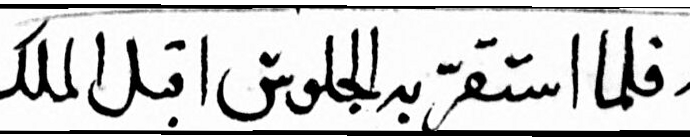
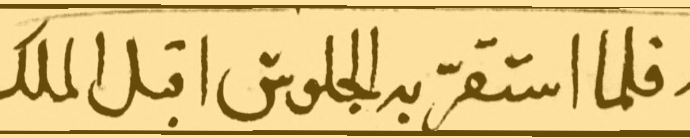
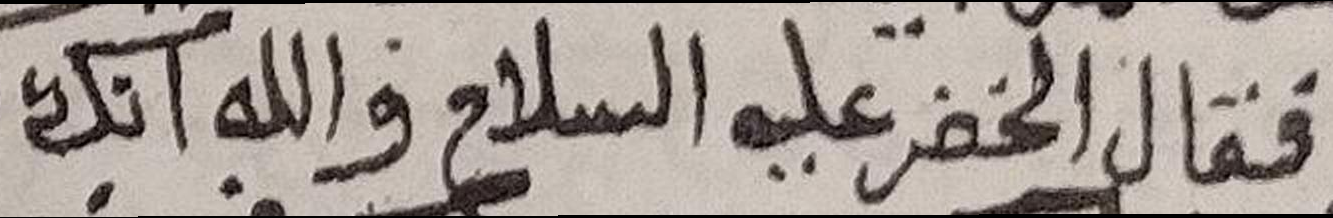
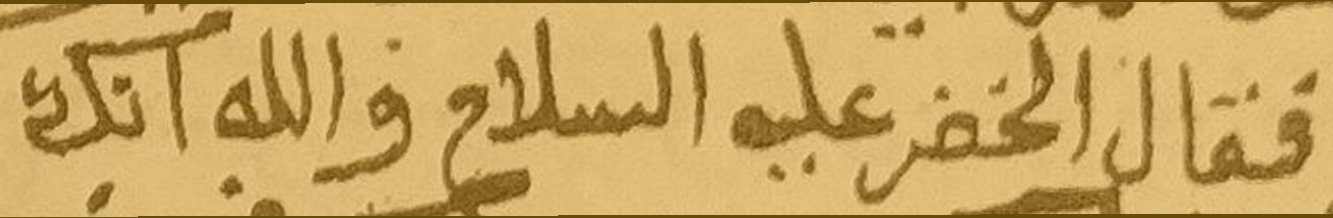

In [208]:
# Fixed positive sample 2 — FUSED only.
if RUN_PHASE1:
    if len(phase1_positive) > 1:
        phase1_show_pair(phase1_positive[1], representation="fused")
    else:
        print("Fixed positive sample 2 unavailable.")


In [209]:
# Fixed positive sample 2 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_positive) > 1:
        phase1_show_pair(phase1_positive[1], representation="context")
    else:
        print("Fixed positive sample 2 unavailable.")


Same fixed sample: ArabicData2:csv:482
CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Fixed positive sample 3 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_positive[2]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [210]:
# Fixed positive sample 3 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_positive) > 2:
        phase1_show_pair(phase1_positive[2], representation="local")
    else:
        print("Fixed positive sample 3 unavailable.")


Fixed positive sample 3 unavailable.


In [211]:
# Fixed positive sample 3 — FUSED only.
if RUN_PHASE1:
    if len(phase1_positive) > 2:
        phase1_show_pair(phase1_positive[2], representation="fused")
    else:
        print("Fixed positive sample 3 unavailable.")


Fixed positive sample 3 unavailable.


In [212]:
# Fixed positive sample 3 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_positive) > 2:
        phase1_show_pair(phase1_positive[2], representation="context")
    else:
        print("Fixed positive sample 3 unavailable.")


Fixed positive sample 3 unavailable.


### Fixed positive sample 4 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_positive[3]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [213]:
# Fixed positive sample 4 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_positive) > 3:
        phase1_show_pair(phase1_positive[3], representation="local")
    else:
        print("Fixed positive sample 4 unavailable.")


Fixed positive sample 4 unavailable.


In [214]:
# Fixed positive sample 4 — FUSED only.
if RUN_PHASE1:
    if len(phase1_positive) > 3:
        phase1_show_pair(phase1_positive[3], representation="fused")
    else:
        print("Fixed positive sample 4 unavailable.")


Fixed positive sample 4 unavailable.


In [215]:
# Fixed positive sample 4 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_positive) > 3:
        phase1_show_pair(phase1_positive[3], representation="context")
    else:
        print("Fixed positive sample 4 unavailable.")


Fixed positive sample 4 unavailable.


### Fixed positive sample 5 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_positive[4]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [216]:
# Fixed positive sample 5 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_positive) > 4:
        phase1_show_pair(phase1_positive[4], representation="local")
    else:
        print("Fixed positive sample 5 unavailable.")


Fixed positive sample 5 unavailable.


In [217]:
# Fixed positive sample 5 — FUSED only.
if RUN_PHASE1:
    if len(phase1_positive) > 4:
        phase1_show_pair(phase1_positive[4], representation="fused")
    else:
        print("Fixed positive sample 5 unavailable.")


Fixed positive sample 5 unavailable.


In [218]:
# Fixed positive sample 5 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_positive) > 4:
        phase1_show_pair(phase1_positive[4], representation="context")
    else:
        print("Fixed positive sample 5 unavailable.")


Fixed positive sample 5 unavailable.


### Fixed negative sample 1 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_negative[0]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [219]:
# Fixed negative sample 1 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_negative) > 0:
        phase1_show_pair(phase1_negative[0], representation="local")
    else:
        print("Fixed negative sample 1 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:429:BookB:485
LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


Same fixed sample: ArabicData2:negative:BookA:429:BookB:485
Separate view: FUSED | sample: ArabicData2:negative:BookA:429:BookB:485
FUSED | pair score: 22.653551128732992 | route flags: ['more than half of within-region transitions repeat a window']


matrix_mean                    0.297294
matrix_std                     0.255005
matrix_min                    -0.382911
matrix_max                     0.918604
matrix_median                  0.315811
row_max_mean                   0.692384
column_max_mean                0.689268
mean_row_peak_margin            0.02999
median_row_peak_margin         0.020914
mean_column_peak_margin        0.030438
median_column_peak_margin      0.020044
path_mean_cosine               0.608371
path_median_cosine             0.601162
path_min_cosine                0.316631
off_path_mean_cosine           0.294845
off_path_median_cosine          0.31345
path_contrast                  0.313526
number_of_matched_pairs              31
distinct_windows_a                   26
distinct_windows_b                   18
horizontal_repeats                    5
vertical_repeats                     13
diagonal_steps                        6
repeat_fraction                     0.6
window_coverage_a              0.412698


,number_of_matched_pairs,path_mean_cosine,path_median_cosine,path_min_cosine,off_path_mean_cosine,off_path_median_cosine,path_contrast,horizontal_repeats,vertical_repeats,diagonal_steps,transition_count,physical_range_a,distinct_windows_a,window_coverage_a,physical_range_b,distinct_windows_b,window_coverage_b,repeat_fraction
predicted_region,,,,,,,,,,,,,,,,,,
0,31,0.608371,0.601162,0.316631,0.294845,0.31345,0.313526,5,13,6,30,"[18, 46]",26,0.412698,"[29, 49]",18,0.285714,0.6


Image display updated to original pixel dimensions; rerun this cell to refresh its images.


"R1 / Line ASource x: [412, 1099)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 687 × 120 pxOriginal-resolution region crop — 687 × 120 px","R1 / Line BSource x: [1155, 2032)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 877 × 236 pxOriginal-resolution region crop — 877 × 236 px"

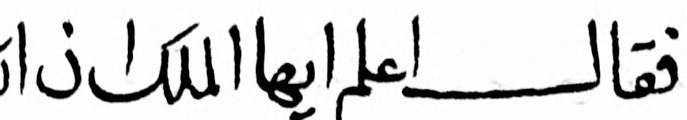
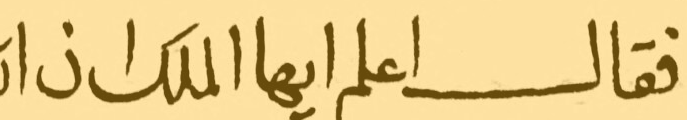
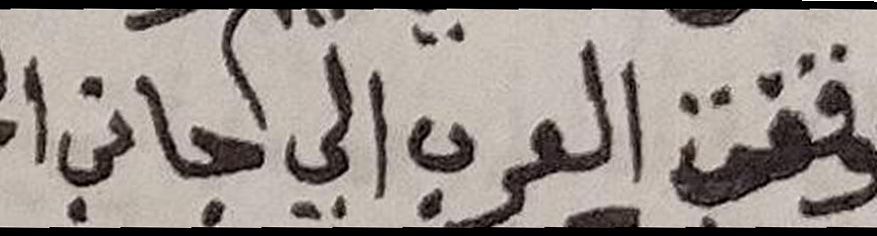
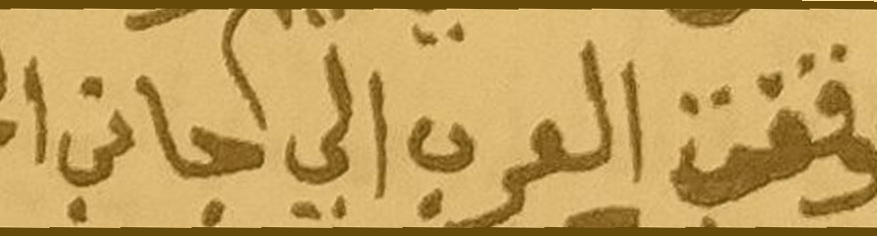

In [220]:
# Fixed negative sample 1 — FUSED only.
if RUN_PHASE1:
    if len(phase1_negative) > 0:
        phase1_show_pair(phase1_negative[0], representation="fused")
    else:
        print("Fixed negative sample 1 unavailable.")


In [221]:
# Fixed negative sample 1 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_negative) > 0:
        phase1_show_pair(phase1_negative[0], representation="context")
    else:
        print("Fixed negative sample 1 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:429:BookB:485
CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Fixed negative sample 2 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_negative[1]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [222]:
# Fixed negative sample 2 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_negative) > 1:
        phase1_show_pair(phase1_negative[1], representation="local")
    else:
        print("Fixed negative sample 2 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:485
LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [223]:
# Fixed negative sample 2 — FUSED only.
if RUN_PHASE1:
    if len(phase1_negative) > 1:
        phase1_show_pair(phase1_negative[1], representation="fused")
    else:
        print("Fixed negative sample 2 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:485
Separate view: FUSED | sample: ArabicData2:negative:BookA:415:BookB:485
FUSED | pair score: 0.0 | route flags: []


matrix_mean                  0.276584
matrix_std                   0.240222
matrix_min                  -0.363985
matrix_max                   0.881781
matrix_median                0.282729
row_max_mean                 0.670838
column_max_mean              0.686602
mean_row_peak_margin         0.033376
median_row_peak_margin       0.020472
mean_column_peak_margin      0.035462
median_column_peak_margin    0.029017
path_mean_cosine                 None
path_median_cosine               None
path_min_cosine                  None
off_path_mean_cosine         0.276584
off_path_median_cosine       0.282729
path_contrast                    None
number_of_matched_pairs             0
distinct_windows_a                  0
distinct_windows_b                  0
horizontal_repeats                  0
vertical_repeats                    0
diagonal_steps                      0
repeat_fraction                   0.0
window_coverage_a                 0.0
window_coverage_b                 0.0
physical_ran

Image display updated to original pixel dimensions; rerun this cell to refresh its images.


In [224]:
# Fixed negative sample 2 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_negative) > 1:
        phase1_show_pair(phase1_negative[1], representation="context")
    else:
        print("Fixed negative sample 2 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:485
CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Fixed negative sample 3 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_negative[2]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [225]:
# Fixed negative sample 3 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_negative) > 2:
        phase1_show_pair(phase1_negative[2], representation="local")
    else:
        print("Fixed negative sample 3 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:482
LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [226]:
# Fixed negative sample 3 — FUSED only.
if RUN_PHASE1:
    if len(phase1_negative) > 2:
        phase1_show_pair(phase1_negative[2], representation="fused")
    else:
        print("Fixed negative sample 3 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:482
Separate view: FUSED | sample: ArabicData2:negative:BookA:415:BookB:482
FUSED | pair score: 0.0 | route flags: []


matrix_mean                  0.277612
matrix_std                   0.241209
matrix_min                  -0.337257
matrix_max                   0.906595
matrix_median                0.283334
row_max_mean                 0.680334
column_max_mean              0.684573
mean_row_peak_margin         0.029508
median_row_peak_margin       0.019137
mean_column_peak_margin      0.029869
median_column_peak_margin     0.02042
path_mean_cosine                 None
path_median_cosine               None
path_min_cosine                  None
off_path_mean_cosine         0.277612
off_path_median_cosine       0.283334
path_contrast                    None
number_of_matched_pairs             0
distinct_windows_a                  0
distinct_windows_b                  0
horizontal_repeats                  0
vertical_repeats                    0
diagonal_steps                      0
repeat_fraction                   0.0
window_coverage_a                 0.0
window_coverage_b                 0.0
physical_ran

Image display updated to original pixel dimensions; rerun this cell to refresh its images.


In [227]:
# Fixed negative sample 3 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_negative) > 2:
        phase1_show_pair(phase1_negative[2], representation="context")
    else:
        print("Fixed negative sample 3 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:482
CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Fixed negative sample 4 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_negative[3]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [228]:
# Fixed negative sample 4 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_negative) > 3:
        phase1_show_pair(phase1_negative[3], representation="local")
    else:
        print("Fixed negative sample 4 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:80
LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


In [229]:
# Fixed negative sample 4 — FUSED only.
if RUN_PHASE1:
    if len(phase1_negative) > 3:
        phase1_show_pair(phase1_negative[3], representation="fused")
    else:
        print("Fixed negative sample 4 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:80
Separate view: FUSED | sample: ArabicData2:negative:BookA:415:BookB:80
FUSED | pair score: 0.0 | route flags: []


matrix_mean                  0.323879
matrix_std                   0.191374
matrix_min                  -0.243431
matrix_max                   0.861234
matrix_median                0.334535
row_max_mean                 0.684845
column_max_mean              0.670036
mean_row_peak_margin         0.039805
median_row_peak_margin       0.026159
mean_column_peak_margin      0.034388
median_column_peak_margin    0.021381
path_mean_cosine                 None
path_median_cosine               None
path_min_cosine                  None
off_path_mean_cosine         0.323879
off_path_median_cosine       0.334535
path_contrast                    None
number_of_matched_pairs             0
distinct_windows_a                  0
distinct_windows_b                  0
horizontal_repeats                  0
vertical_repeats                    0
diagonal_steps                      0
repeat_fraction                   0.0
window_coverage_a                 0.0
window_coverage_b                 0.0
physical_ran

Image display updated to original pixel dimensions; rerun this cell to refresh its images.


In [230]:
# Fixed negative sample 4 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_negative) > 3:
        phase1_show_pair(phase1_negative[3], representation="context")
    else:
        print("Fixed negative sample 4 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:415:BookB:80
CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


### Fixed negative sample 5 — LOCAL → FUSED → CONTEXT

The three code cells below use the same pair from `phase1_negative[4]`.
Rerun any representation cell independently; the selected pair stays fixed.


In [231]:
# Fixed negative sample 5 — LOCAL only.
if RUN_PHASE1:
    if len(phase1_negative) > 4:
        phase1_show_pair(phase1_negative[4], representation="local")
    else:
        print("Fixed negative sample 5 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:424:BookB:80
LOCAL hidden by SHOW_REPRESENTATIONS = ['fused'].


Same fixed sample: ArabicData2:negative:BookA:424:BookB:80
Separate view: FUSED | sample: ArabicData2:negative:BookA:424:BookB:80
FUSED | pair score: 25.280671406186368 | route flags: ['more than half of within-region transitions repeat a window', 'route jumps over physical A windows', 'route jumps over physical B windows']


matrix_mean                    0.344929
matrix_std                     0.198899
matrix_min                    -0.257022
matrix_max                     0.884967
matrix_median                  0.362858
row_max_mean                    0.70797
column_max_mean                0.674654
mean_row_peak_margin           0.035296
median_row_peak_margin          0.02212
mean_column_peak_margin        0.025085
median_column_peak_margin      0.018056
path_mean_cosine               0.600849
path_median_cosine             0.583745
path_min_cosine                0.182729
off_path_mean_cosine           0.342323
off_path_median_cosine         0.360328
path_contrast                  0.258525
number_of_matched_pairs              40
distinct_windows_a                   32
distinct_windows_b                   26
horizontal_repeats                    8
vertical_repeats                     14
diagonal_steps                       12
repeat_fraction                0.564103
window_coverage_a              0.507937


,number_of_matched_pairs,path_mean_cosine,path_median_cosine,path_min_cosine,off_path_mean_cosine,off_path_median_cosine,path_contrast,horizontal_repeats,vertical_repeats,diagonal_steps,transition_count,physical_range_a,distinct_windows_a,window_coverage_a,physical_range_b,distinct_windows_b,window_coverage_b,repeat_fraction
predicted_region,,,,,,,,,,,,,,,,,,
0,40,0.600849,0.583745,0.182729,0.342323,0.360328,0.258525,8,14,12,39,"[1, 36]",32,0.507937,"[33, 61]",26,0.412698,0.564103


Image display updated to original pixel dimensions; rerun this cell to refresh its images.


"R1 / Line ASource x: [23, 885)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 862 × 129 pxOriginal-resolution region crop — 862 × 129 px","R1 / Line BSource x: [1507, 2879)Transcript occurrence(s): No word hypothesis to compareOriginal-resolution region crop — 1372 × 295 pxOriginal-resolution region crop — 1372 × 295 px"

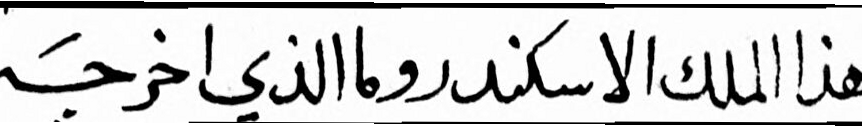
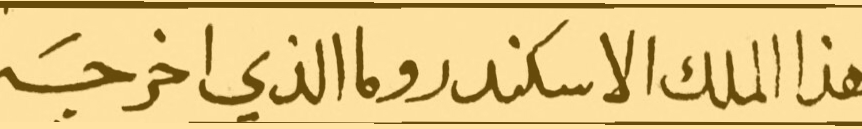
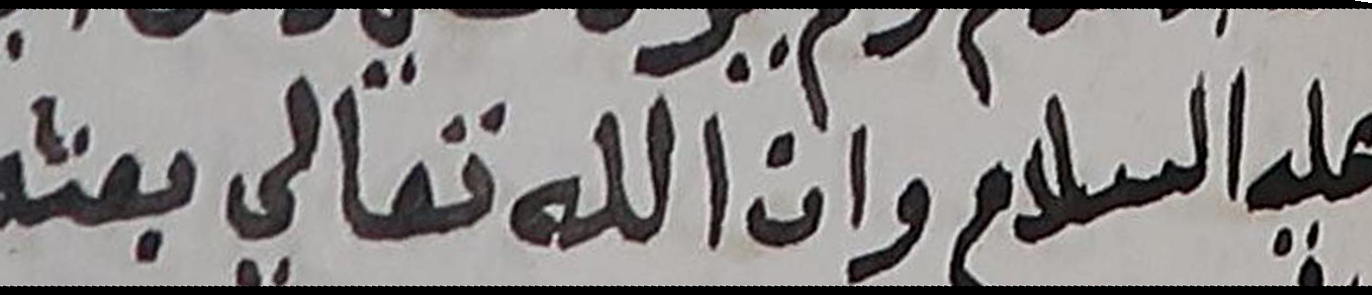
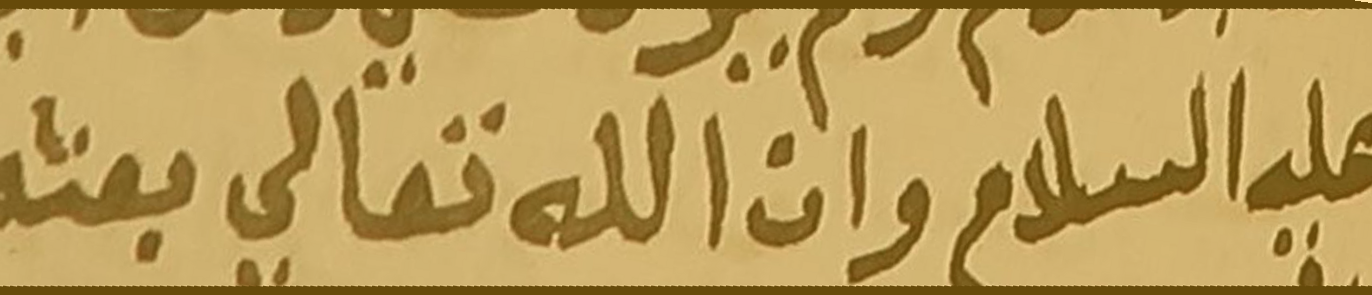

In [232]:
# Fixed negative sample 5 — FUSED only.
if RUN_PHASE1:
    if len(phase1_negative) > 4:
        phase1_show_pair(phase1_negative[4], representation="fused")
    else:
        print("Fixed negative sample 5 unavailable.")


In [233]:
# Fixed negative sample 5 — CONTEXT only.
if RUN_PHASE1:
    if len(phase1_negative) > 4:
        phase1_show_pair(phase1_negative[4], representation="context")
    else:
        print("Fixed negative sample 5 unavailable.")


Same fixed sample: ArabicData2:negative:BookA:424:BookB:80
CONTEXT hidden by SHOW_REPRESENTATIONS = ['fused'].


## C. Representation progression for the fixed examples

Read each positive table as CNN/LOCAL → Transformer/CONTEXT → FUSION/FUSED.
Scores are length-dependent matcher objectives, not probabilities. Peak margins
compare the best and second-best raw cosine values. Both row and column uniqueness
matter. Each table uses one physical pair across all three representations.

In [234]:
PHASE1_PROGRESSION_METRICS = ['pair_score', 'matrix_max', 'mean_row_peak_margin',
    'mean_column_peak_margin', 'path_mean_cosine', 'off_path_mean_cosine', 'path_contrast',
    'distinct_windows_a', 'distinct_windows_b', 'repeat_fraction']
if RUN_PHASE1:
    phase1_fixed_table = pd.DataFrame(phase1_fixed_rows)
    phase1_progression = {}
    for pair in phase1_positive:
        progression = pd.DataFrame({rep.upper(): {
            metric: phase1_results[(pair['sample_id'], rep)]['metrics'].get(metric)
            for metric in PHASE1_PROGRESSION_METRICS} for rep in REPRESENTATIONS})
        phase1_progression[pair['sample_id']] = progression
        print(pair['sample_id']); display(progression.rename_axis('metric'))
    if not phase1_fixed_table.empty:
        display(phase1_fixed_table.groupby(['target', 'representation'])[
            ['pair_score', 'matrix_max', 'mean_row_peak_margin', 'path_contrast', 'repeat_fraction']].mean())

ArabicData2:csv:331


,LOCAL,CONTEXT,FUSED
metric,,,
pair_score,0.000000,0.000000,0.000000
matrix_max,0.845900,0.923582,0.893147
mean_row_peak_margin,0.047401,0.036663,0.046447
mean_column_peak_margin,0.034201,0.026156,0.034348
path_mean_cosine,NaN,NaN,NaN
off_path_mean_cosine,0.248717,0.367439,0.264975
path_contrast,NaN,NaN,NaN
distinct_windows_a,0.000000,0.000000,0.000000
distinct_windows_b,0.000000,0.000000,0.000000


ArabicData2:csv:482


,LOCAL,CONTEXT,FUSED
metric,,,
pair_score,0.000000,33.635722,32.970332
matrix_max,0.870470,0.938621,0.913248
mean_row_peak_margin,0.038095,0.024019,0.032579
mean_column_peak_margin,0.041330,0.026814,0.035748
path_mean_cosine,NaN,0.708043,0.607581
off_path_mean_cosine,0.272797,0.406062,0.291653
path_contrast,NaN,0.301981,0.315928
distinct_windows_a,0.000000,33.000000,27.000000
distinct_windows_b,0.000000,33.000000,29.000000


pair_score  matrix_max  mean_row_peak_margin  \
target representation                                                 
0      context          19.284153    0.913058              0.025526   
       fused             9.586845    0.890636              0.033595   
       local             0.000000    0.866951              0.042755   
1      context          16.817861    0.931101              0.030341   
       fused            16.485166    0.903197              0.039513   
       local             0.000000    0.858185              0.042748   

                       path_contrast  repeat_fraction  
target representation                                  
0      context              0.240734         0.553807  
       fused                0.286026         0.232821  
       local                     NaN         0.000000  
1      context              0.301981         0.346939  
       fused                0.315928         0.341463  
       local                     NaN         0.000000

## D. Feature-population diagnostics

Reuse `feature_diagnostics` over up to 100 saved-test lines and 1,024 windows,
selected with PHASE1_SEED independently of detailed examples. Report its source
images and warnings in `phase1_feature_report`. Pairwise cosine mixes within-line
and cross-line windows; high similarity alone does not establish collapse.

In [235]:
if RUN_PHASE1:
    phase1_feature_report = feature_diagnostics(phase1_session,
        max_lines=PHASE1_COLLAPSE_MAX_LINES, max_windows=PHASE1_COLLAPSE_MAX_WINDOWS)
    phase1_collapse_rows = []
    for rep, values in phase1_feature_report['representations'].items():
        cos = values.get('pairwise_cosine', {})
        phase1_collapse_rows.append(dict(representation=rep.upper(),
            lines=values.get('lines'), windows=values.get('windows'),
            norm_mean=values.get('norm_mean'), norm_std=values.get('norm_std'),
            feature_std=values.get('feature_std_mean'), pairwise_cos_mean=cos.get('mean'),
            pairwise_cos_median=cos.get('median'), pairwise_cos_q25=cos.get('q25'),
            pairwise_cos_q75=cos.get('q75'), warning='; '.join(values.get('warnings', []))))
    phase1_collapse_table = pd.DataFrame(phase1_collapse_rows).set_index('representation')
    display(phase1_collapse_table)
    print(phase1_feature_report['note'])

,lines,windows,norm_mean,norm_std,feature_std,pairwise_cos_mean,pairwise_cos_median,pairwise_cos_q25,pairwise_cos_q75,warning
representation,,,,,,,,,,
LOCAL,12,756,9.023371,3.091887e+00,0.726733,0.276340,0.271140,0.145318,0.398135,
CONTEXT,12,756,11.329301,2.304113e-03,0.733172,0.432908,0.464631,0.270725,0.615537,
FUSED,12,756,1.000000,3.973643e-08,0.071957,0.311132,0.323786,0.145656,0.480763,


Seeded window sample; pairwise statistics include within-line and cross-line pairs, not a collapse verdict.


## E. Population evaluation — deferred

Inspect the fixed examples above. Population accuracy will be evaluated after mask annotation.


In [236]:
# Retained population-evaluation section.
print("Population evaluation disabled during qualitative inspection.")


Population evaluation disabled during qualitative inspection.


### Population mask accuracy — deferred

No mask accuracy is computed before annotation.


In [237]:
# Retained mask-accuracy section.
print("Mask accuracy deferred until annotation.")


Mask accuracy deferred until annotation.


## F. Padding and physical-window sanity report

Assertions above verify that all LOCAL/CONTEXT/FUSED features contain exactly the
valid windows, and cosine shape is valid A × valid B. Invalid windows carry -1
only in the full grid. RTL reversal preserves physical identities. Source-pixel
intervals are checked against the original crop/resize geometry, and mask support
is rebuilt with the existing `region_mask`. No-padding runs are explicitly reported;
they do not prove behavior for padded inputs (covered by repository tests).

In [238]:
if RUN_PHASE1:
    phase1_sanity_table = pd.DataFrame(phase1_sanity_rows)
    display(phase1_sanity_table)
    print('All selected-pair/representation indexing assertions passed.')
    print('Observed padded windows:', int(phase1_sanity_table['padded_windows'].sum()) if not phase1_sanity_table.empty else 0)

,sample_id,representation,cosine_shape,line,total_windows,valid_windows,padded_windows,physical_range,rtl,status
0,ArabicData2:csv:331,local,"(63, 63)",A,63,63,0,"[0, 62]",True,passed
1,ArabicData2:csv:331,local,"(63, 63)",B,63,63,0,"[0, 62]",True,passed
2,ArabicData2:csv:331,context,"(63, 63)",A,63,63,0,"[0, 62]",True,passed
3,ArabicData2:csv:331,context,"(63, 63)",B,63,63,0,"[0, 62]",True,passed
4,ArabicData2:csv:331,fused,"(63, 63)",A,63,63,0,"[0, 62]",True,passed
5,ArabicData2:csv:331,fused,"(63, 63)",B,63,63,0,"[0, 62]",True,passed
6,ArabicData2:csv:482,local,"(63, 63)",A,63,63,0,"[0, 62]",True,passed
7,ArabicData2:csv:482,local,"(63, 63)",B,63,63,0,"[0, 62]",True,passed
8,ArabicData2:csv:482,context,"(63, 63)",A,63,63,0,"[0, 62]",True,passed
9,ArabicData2:csv:482,context,"(63, 63)",B,63,63,0,"[0, 62]",True,passed


All selected-pair/representation indexing assertions passed.
Observed padded windows: 0


## G. Qualitative review notes

Inspect whether accepted routes and predicted regions follow plausible shared
writing in the source lines. Compare the same pair across LOCAL, FUSED and CONTEXT.
Use similarity contrast, repeated-window warnings and indexing checks to understand
behavior. Correctness and localization accuracy require the future mask annotations.


In [239]:
if RUN_PHASE1:
    assert json.dumps(resolved_match_settings(phase1_session.settings), sort_keys=True) == phase1_settings_json
    assert json.dumps(resolved_match_settings(session.settings), sort_keys=True) == phase1_settings_json
    print('Qualitative review complete: inspect predicted overlays, routes and heatmaps above.')
    print('Matcher settings unchanged. Ground-truth masks and quantitative scoring were not used.')


Qualitative review complete: inspect predicted overlays, routes and heatmaps above.
Matcher settings unchanged. Ground-truth masks and quantitative scoring were not used.
